# Explainable and Fair Heart Disease Prediction: Understanding Bias and Fairness Trade-offs
## Kaggle Cardiovascular Disease Dataset
This notebook repeats the same analysis on a second dataset, investigating sources of gender bias in cardiovascular disease prediction using explainability tools, and measuring fairness trade-offs across five metrics. Three models are compared (Logistic Regression, Random Forest and XGBoost), explained using SHAP and LIME, and audited for fairness between male and female patients.

## 1. Data Loading and Exploration

In [1]:
# Import libraries for data analysis, visualisation and machine learning

# Pandas for data manipulation and NumPy for numerical operations
import pandas as pd
import numpy as np

# Seaborn and matplotlib for data visualisation
import seaborn as sns
from matplotlib import pyplot as plt

# Display plots inline in the notebook
%matplotlib inline

# Set a clean and consistent style for all plots in the notebook
sns.set_style('white')

# Set consistent font sizes for titles, axis labels and ticks
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Keep the original dtype when filling missing values rather than silently downcasting
pd.set_option('future.no_silent_downcasting', True)

# Fix the random seed so that results are reproducible
random_state = 42

In [2]:
# Load the cardiovascular disease dataset from the data folder
# This file is separated by semicolons rather than commas, so the separator is set explicitly
df = pd.read_csv('../data/cardio_train.csv', sep=';')

# List all column names to understand the structure of the dataset
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

The dataset contains the following columns. The descriptions are based on the original Kaggle dataset documentation, with the column names matching this version of the dataset.

| Column | Description |
|---|---|
| `id` | Unique identifier for each patient |
| `age` | Age of the patient in days, converted to years during preparation |
| `gender` | Gender of the patient (1 = women, 2 = men) |
| `height` | Height of the patient in centimetres |
| `weight` | Weight of the patient in kilograms |
| `ap_hi` | Systolic blood pressure |
| `ap_lo` | Diastolic blood pressure |
| `cholesterol` | Cholesterol level (1 = normal, 2 = above normal, 3 = well above normal) |
| `gluc` | Glucose level (1 = normal, 2 = above normal, 3 = well above normal) |
| `smoke` | Whether the patient smokes (0 = no, 1 = yes) |
| `alco` | Whether the patient drinks alcohol (0 = no, 1 = yes) |
| `active` | Whether the patient is physically active (0 = no, 1 = yes) |
| `cardio` | Presence or absence of cardiovascular disease (0 = no, 1 = yes) |

In [3]:
# Check the number of rows and columns in the dataset
print('The dataset has {} rows and {} columns'.format(df.shape[0], df.shape[1]))

# Display the first five rows to see what the data looks like
df.head()

The dataset has 70000 rows and 13 columns


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [4]:
# Display data types, non-null counts and memory usage for each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [5]:
# Summary statistics to check the range, spread and any clinically impossible values such as a negative or extreme blood pressure
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
# Count the biologically implausible values, which need attention during preprocessing
# Some values are logically impossible, such as a blood pressure that is zero or negative, or a systolic pressure lower than the diastolic one
print('Number of patients with zero or negative systolic pressure: {}'.format((df['ap_hi'] <= 0).sum()))
print('Number of patients with zero or negative diastolic pressure: {}'.format((df['ap_lo'] <= 0).sum()))
print('Number of patients where systolic is lower than diastolic: {}'.format((df['ap_hi'] < df['ap_lo']).sum()))

# Other values fall outside the range that is physically possible in a living adult patient
print('Number of patients with systolic pressure above 250: {}'.format((df['ap_hi'] > 250).sum()))
print('Number of patients with diastolic pressure outside 30 to 300: {}'.format(((df['ap_lo'] < 30) | (df['ap_lo'] > 300)).sum()))
print('Number of patients with height outside 100 to 250 cm: {}'.format(((df['height'] < 100) | (df['height'] > 250)).sum()))
print('Number of patients with weight outside 20 to 200 kg: {}'.format(((df['weight'] < 20) | (df['weight'] > 200)).sum()))

Number of patients with zero or negative systolic pressure: 7
Number of patients with zero or negative diastolic pressure: 22
Number of patients where systolic is lower than diastolic: 1234
Number of patients with systolic pressure above 250: 40
Number of patients with diastolic pressure outside 30 to 300: 1006
Number of patients with height outside 100 to 250 cm: 29
Number of patients with weight outside 20 to 200 kg: 2


The `describe()` output revealed that several columns contain values that are biologically implausible. Some are logically impossible, such as a blood pressure that is zero or negative, or a systolic pressure lower than the diastolic one: 7 patients have a systolic pressure of zero or below, 22 have a diastolic pressure of zero or below, and 1234 have a systolic pressure lower than their diastolic pressure. Others fall outside the range that is physically possible in a living adult patient: 40 patients have a systolic pressure above 250, 1006 have a diastolic pressure outside 30 to 300, 29 have a height outside 100 to 250 cm, and 2 have a weight outside 20 to 200 kg. These thresholds were set to exclude values that are physically impossible in a living adult, well outside any survivable range, so they remove clear data-entry errors rather than unusual but real measurements. They are removed below, before the analysis begins.

### Check data quality

Missing values and duplicated rows are checked to identify any data quality issues before analysis.

In [7]:
# Check for missing values in each column, sorted from highest to lowest
df.isnull().sum().sort_values(ascending=False)

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

In [8]:
# Check for duplicated rows as part of the data quality checks
print('Number of duplicated rows: {}'.format(df.duplicated().sum()))

Number of duplicated rows: 0


There are no missing values in any column, so no imputation is needed for missingness, and no fully duplicated rows are found. The data quality issues in this dataset are therefore not missing or duplicated data, but the impossible blood pressure values identified above, which are removed below.

In [9]:
# Drop the id column as it is just a patient identifier with no predictive value
print('id has no analytic value: {} unique values, one per patient ... so I can drop it'
      .format(df['id'].nunique()))
df = df.drop(['id'], axis=1)

id has no analytic value: 70000 unique values, one per patient ... so I can drop it


### Remove the biologically implausible values

The values that are biologically implausible are removed before the analysis, so that the plots and the models are not distorted by them. A row is removed if the blood pressure is logically impossible (zero or negative, or systolic lower than diastolic), or if a measurement falls outside the range that is physically possible in a living adult patient: systolic above 250, diastolic outside 30 to 300, height outside 100 to 250 cm, or weight outside 20 to 200 kg. These are treated as data entry errors rather than real measurements. Values that are unusual but still physically possible are kept, since they may represent genuine patients, and are handled with the modelling later on.

In [10]:
# Remove the rows with biologically implausible values
# These are values that cannot occur in a living adult patient, so they are treated as data entry errors
print('Ranges before cleaning:')
print('ap_hi {} to {}, ap_lo {} to {}'.format(df['ap_hi'].min(), df['ap_hi'].max(), df['ap_lo'].min(), df['ap_lo'].max()))
print('height {} to {}, weight {} to {}'.format(df['height'].min(), df['height'].max(), df['weight'].min(), df['weight'].max()))
impossible = (df['ap_hi'] <= 0) | (df['ap_lo'] <= 0) | (df['ap_hi'] < df['ap_lo'])
impossible = impossible | (df['ap_hi'] > 250) | (df['ap_lo'] < 30) | (df['ap_lo'] > 300)
impossible = impossible | (df['height'] < 100) | (df['height'] > 250)
impossible = impossible | (df['weight'] < 20) | (df['weight'] > 200)
print('\nNumber of rows removed: {}'.format(impossible.sum()))
df = df[~impossible]
print('The dataset has {} rows after cleaning\n'.format(df.shape[0]))
print('Ranges after cleaning:')
print('ap_hi {} to {}, ap_lo {} to {}'.format(df['ap_hi'].min(), df['ap_hi'].max(), df['ap_lo'].min(), df['ap_lo'].max()))
print('height {} to {}, weight {} to {}'.format(df['height'].min(), df['height'].max(), df['weight'].min(), df['weight'].max()))

Ranges before cleaning:
ap_hi -150 to 16020, ap_lo -70 to 11000
height 55 to 250, weight 10.0 to 200.0

Number of rows removed: 1347
The dataset has 68653 rows after cleaning

Ranges after cleaning:
ap_hi 60 to 240, ap_lo 30 to 182
height 100 to 250, weight 21.0 to 200.0


## 2. Exploratory Data Analysis

The target variable, numerical features and categorical features are analysed to understand patterns in the data and to see which features might be useful for predicting cardiovascular disease.

In [11]:
# Save a backup copy of the dataframe before exploratory analysis and any transformations, so the original cleaned data can be restored if needed
df_original = df.copy()

The age column is recorded in days, so it is converted to years to make it easier to interpret before the features are explored.

In [12]:
# Convert age from days to years so the values are easier to interpret
df['age'] = df['age'] / 365
print('Age in years:\n{}'.format(df['age'].describe()))

Age in years:
count    68653.000000
mean        53.328087
std          6.761951
min         29.583562
25%         48.378082
50%         53.978082
75%         58.421918
max         64.967123
Name: age, dtype: float64


In [13]:
# The target in this dataset is the cardio column, which is already binary: 0 = no cardiovascular disease, 1 = cardiovascular disease. It is copied to a column named target to keep the rest of the analysis consistent
df['target'] = df['cardio']

# Check the distribution of the binary target as counts and proportions
print('Counts for the target are:\n{}'.format(df['target'].value_counts()))
print('\nProportions for the target are:\n{}'.format(df['target'].value_counts(normalize=True)))

Counts for the target are:
target
0    34688
1    33965
Name: count, dtype: int64

Proportions for the target are:
target
0    0.505266
1    0.494734
Name: proportion, dtype: float64


The binary target is almost perfectly balanced, with 49.47% of patients having cardiovascular disease and 50.53% not. This means class imbalance is not a concern in this dataset. The more important question for this study is how this rate differs between male and female patients, which is examined next.

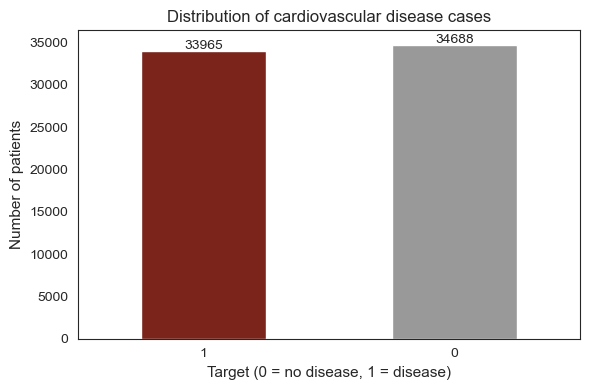

In [14]:
# Visualise the distribution of the binary target with a bar chart
# The categories are kept in a fixed order so that disease (1) is always shown in red and no disease (0) in grey
counts = df['target'].value_counts().reindex([1, 0])
ax = counts.plot(kind='bar', figsize=(6, 4), color=['#7b241c', '#999999'])
plt.title('Distribution of cardiovascular disease cases')
plt.xlabel('Target (0 = no disease, 1 = disease)')
plt.ylabel('Number of patients')
plt.xticks(rotation=0)

# Add the count on top of each bar for readability
for i, count in enumerate(counts):
    ax.text(i, count + 200, str(count), ha='center')

plt.tight_layout()
plt.show()

### Gender base rates — the core of the fairness analysis

The rate of cardiovascular disease is compared between male and female patients. A large difference in base rates between the two groups is what makes fairness trade-offs unavoidable, so this is the central observation for the rest of the analysis.

In [15]:
# Compare the cardiovascular disease rate between male and female patients
# The crosstab shows counts, and normalising by row gives the rate within each gender
gender_counts = pd.crosstab(df['gender'], df['target'])
print('Counts of disease by gender:\n{}'.format(gender_counts))

gender_rates = pd.crosstab(df['gender'], df['target'], normalize='index')
print('\nProportion of disease within each gender:\n{}'.format(gender_rates))

Counts of disease by gender:
target      0      1
gender              
1       22712  22007
2       11976  11958

Proportion of disease within each gender:
target         0         1
gender                    
1       0.507883  0.492117
2       0.500376  0.499624


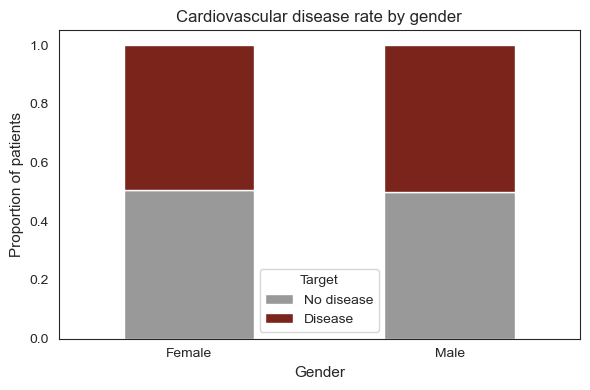

In [16]:
# Visualise the disease rate within each gender as a stacked bar chart
# Each bar is one gender, split into the proportion with and without disease
ax = gender_rates.plot(kind='bar', stacked=True, figsize=(6, 4), color=['#999999', '#7b241c'])
plt.title('Cardiovascular disease rate by gender')
plt.xlabel('Gender')
plt.ylabel('Proportion of patients')

# The gender column is coded as 1 and 2, so the tick labels are set to the readable names
ax.set_xticklabels(['Female', 'Male'], rotation=0)
plt.legend(['No disease', 'Disease'], title='Target')
plt.tight_layout()
plt.show()

There is almost no difference in the cardiovascular disease rate between the two genders. In this dataset 49.96% of male patients have the disease, compared with 49.21% of female patients, which is a gap of only 0.75 percentage points. This gap comes from the data itself rather than from any modelling choice.

This near-equal base rate is important for the fairness analysis. When two groups have very similar base rates, the mathematical tension between the different fairness criteria is much weaker, so it is possible to satisfy several of them at the same time without one badly worsening another. This dataset is therefore expected to show only a minimal trade-off, which is examined in the fairness analysis later on.

### Age distribution by gender

Age is a strong risk factor for cardiovascular disease, so the age distribution is compared between male and female patients. This shows whether the two groups are similar in age, which is useful background for interpreting the rest of the analysis.

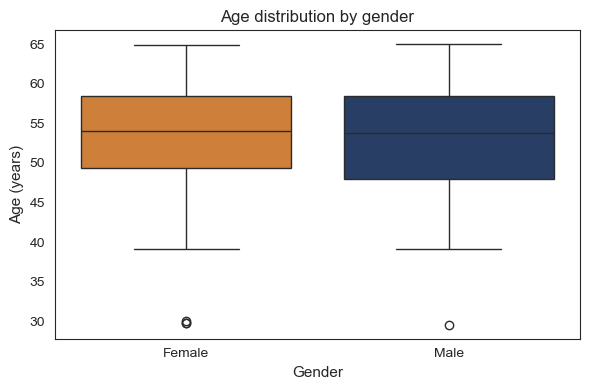

Mean age by gender:
gender
1    53.443149
2    53.113102
Name: age, dtype: float64


In [17]:
# Compare the age distribution between male and female patients
plt.figure(figsize=(6, 4))
ax = sns.boxplot(data=df, x='gender', y='age', hue='gender', palette=['#e67e22', '#1f3b6f'], legend=False)
plt.title('Age distribution by gender')
plt.xlabel('Gender')
plt.ylabel('Age (years)')

# The gender column is coded as 1 and 2, so the tick labels are set to the readable names
ax.set_xticks([0, 1])
ax.set_xticklabels(['Female', 'Male'])
plt.tight_layout()
plt.show()

# Print the mean age for each gender to support the plot
print('Mean age by gender:\n{}'.format(df.groupby('gender')['age'].mean()))

The two genders have very similar ages: the mean age is 53.44 years for female patients and 53.11 years for male patients, a difference of well under one year. Since the two groups are so close in age, age is not a source of difference between them, and the small base rate gap seen earlier is not driven by age.

### Numerical features and cardiovascular disease

The five numerical features (age, height, weight, systolic and diastolic blood pressure) are examined next. Their distributions are checked first, then they are compared between the sexes and between patients with and without cardiovascular disease, and finally their correlations with the target are summarised in a heatmap. This shows which numerical measurements are most strongly related to cardiovascular disease.

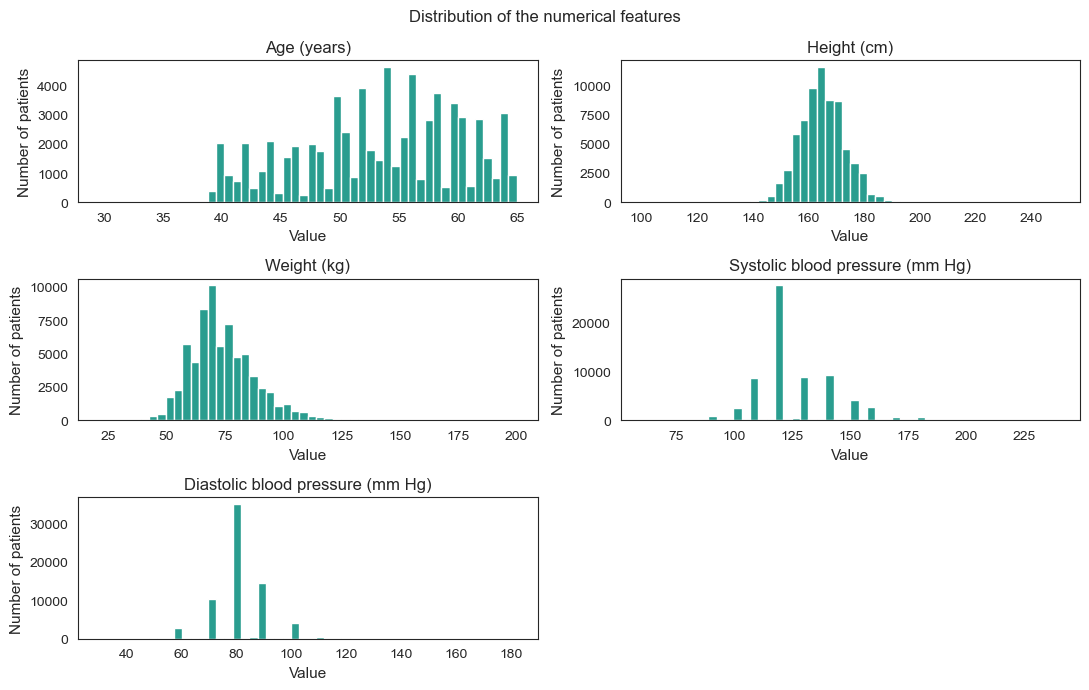

In [18]:
# Look at the distribution of the main numerical features with histograms
# The x-axis is the value of each feature and the y-axis is the number of patients in that range
numerical_cols = ['age', 'height', 'weight', 'ap_hi', 'ap_lo']
readable_names = ['Age (years)', 'Height (cm)', 'Weight (kg)', 'Systolic blood pressure (mm Hg)', 'Diastolic blood pressure (mm Hg)']

df_plot = df[numerical_cols].copy()
df_plot.columns = readable_names

axes = df_plot.hist(figsize=(11, 7), color='#2a9d8f', edgecolor='white', grid=False, bins=50)
# Label both axes on each subplot so it is clear what they show
for row in axes:
    for ax in row:
        ax.set_xlabel('Value')
        ax.set_ylabel('Number of patients')
        
plt.suptitle('Distribution of the numerical features')
plt.tight_layout()
plt.show()

The histograms show that the numerical features fall within plausible physiological ranges after cleaning, with no extreme values left. Age is spread across a wide range with slightly more patients towards the older end, while height is roughly symmetric around 165 cm and weight is right-skewed, with a longer tail towards heavier patients. The two blood pressure features show clear spikes at round numbers such as 120 and 80, because blood pressure is usually recorded in rounded values rather than exact ones. None of the features show the impossible values that were removed earlier, which confirms the cleaning step worked as intended.

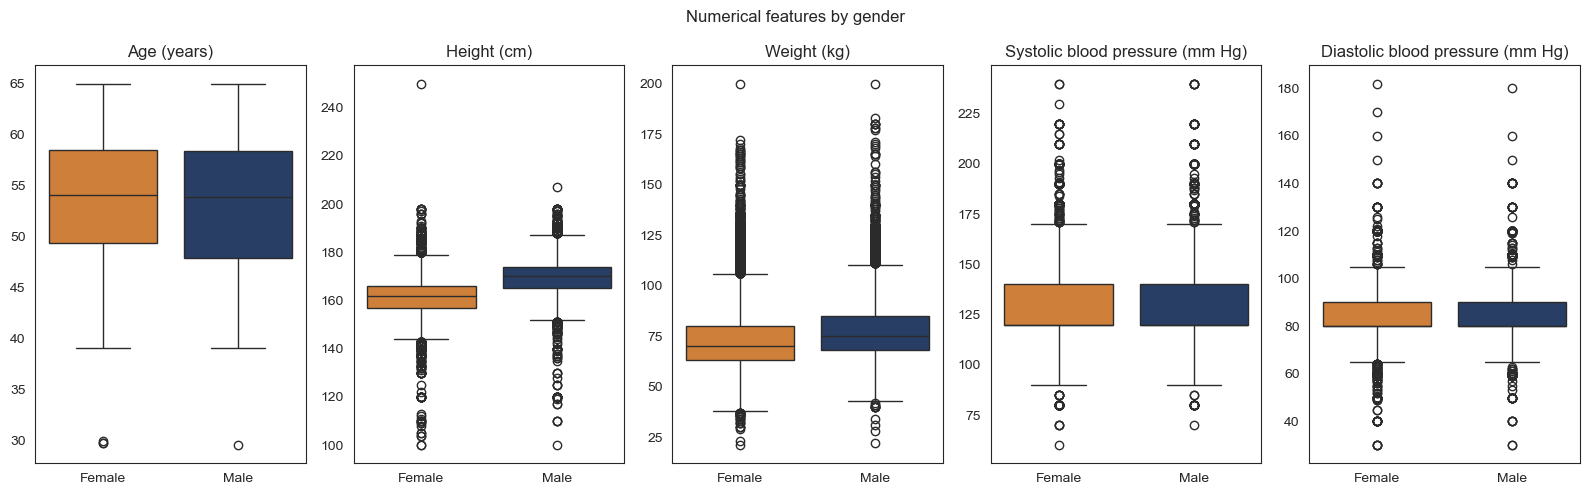

In [19]:
# Compare the numerical features between male and female patients with boxplots
# This shows whether the two genders differ in their clinical measurements
numerical_cols = ['age', 'height', 'weight', 'ap_hi', 'ap_lo']
feature_labels = {'age': 'Age (years)', 'height': 'Height (cm)', 'weight': 'Weight (kg)', 'ap_hi': 'Systolic blood pressure (mm Hg)', 'ap_lo': 'Diastolic blood pressure (mm Hg)'}

fig, axes = plt.subplots(1, 5, figsize=(16, 5))
for i, col in enumerate(numerical_cols):
    sns.boxplot(data=df, x='gender', y=col, hue='gender', palette=['#e67e22', '#1f3b6f'], legend=False, ax=axes[i])
    axes[i].set_title(feature_labels[col])
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')
    
    # The gender column is coded as 1 and 2, so the tick labels are set to the readable names
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['Female', 'Male'])

plt.suptitle('Numerical features by gender')
plt.tight_layout()
plt.show()

The boxplots show that the two genders differ mainly in body measurements rather than in their clinical readings. Male patients are noticeably taller, with a median height of around 170 cm compared with about 162 cm for female patients, and they are also somewhat heavier. In contrast, age and the two blood pressure features are very similar between the two groups, with the boxes overlapping almost completely. These differences are physiologically expected and matter for fairness, because if a feature behaves differently across the genders, a model may rely on it differently for male and female patients. This is an early sign of where gender differences could enter the model, and it is examined more directly later with gender-stratified SHAP.

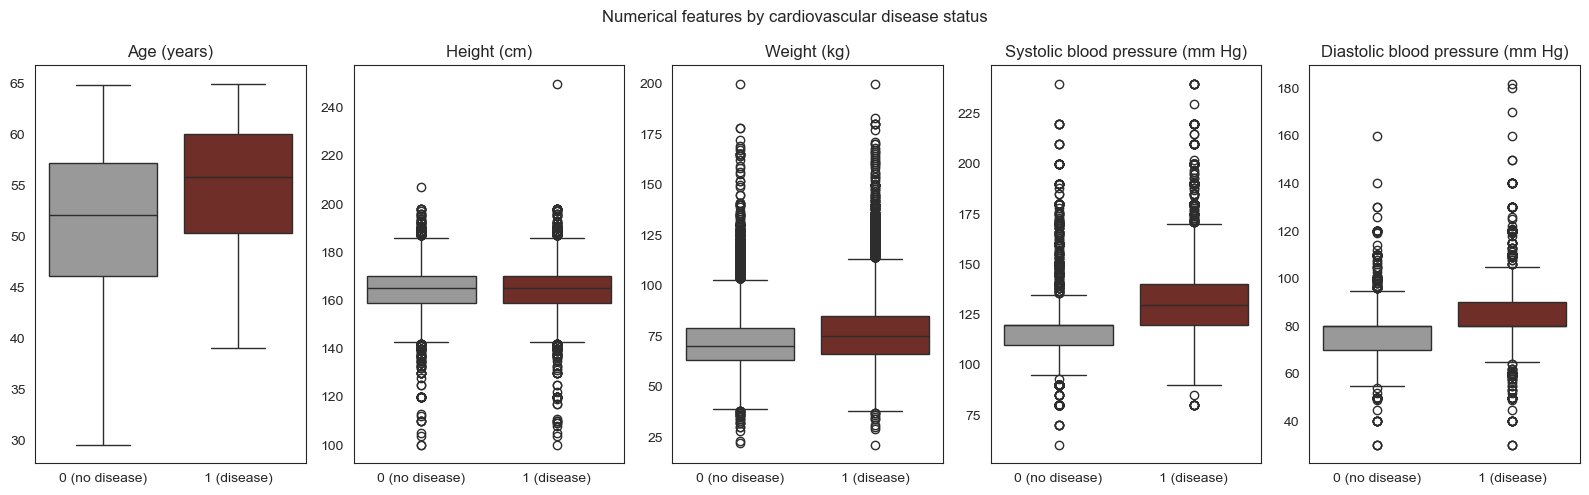

In [20]:
# Compare the numerical features between patients with and without cardiovascular disease with boxplots
# This shows which measurements separate the two groups and are likely to be useful predictors
numerical_cols = ['age', 'height', 'weight', 'ap_hi', 'ap_lo']
feature_labels = {'age': 'Age (years)', 'height': 'Height (cm)', 'weight': 'Weight (kg)', 'ap_hi': 'Systolic blood pressure (mm Hg)', 'ap_lo': 'Diastolic blood pressure (mm Hg)'}

fig, axes = plt.subplots(1, 5, figsize=(16, 5))
for i, col in enumerate(numerical_cols):
    sns.boxplot(data=df, x='target', y=col, hue='target', palette=['#999999', '#7b241c'], legend=False, ax=axes[i])
    axes[i].set_title(feature_labels[col])
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['0 (no disease)', '1 (disease)'])
    
plt.suptitle('Numerical features by cardiovascular disease status')
plt.tight_layout()
plt.show()

The boxplots show which measurements separate patients with and without cardiovascular disease. The clearest difference is in systolic blood pressure: patients with disease tend to have noticeably higher values, and diastolic blood pressure follows the same pattern. Weight and age also separate the two groups, with patients who have disease being somewhat heavier and older. Height, in contrast, barely separates them, with the two boxes overlapping almost completely. This visual check gives an early indication of which features the models are likely to rely on, which can later be compared against the SHAP results.

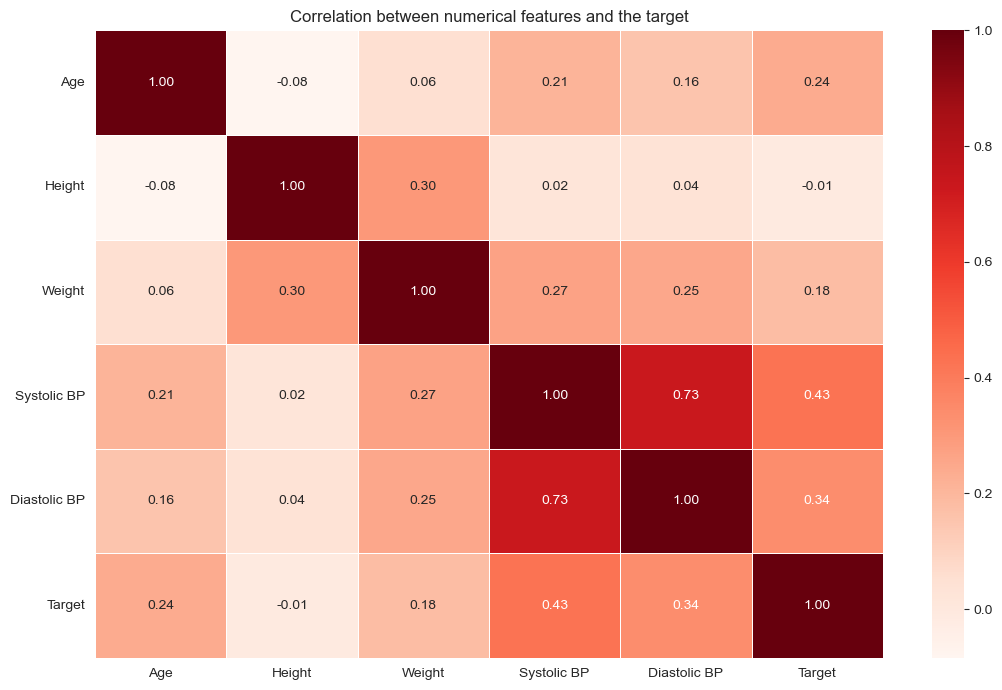

Correlation of each feature with the target:
Target          1.000000
Systolic BP     0.428002
Diastolic BP    0.339584
Age             0.239330
Weight          0.179769
Height         -0.011747
Name: Target, dtype: float64

Correlation between features:
                   Age    Height    Weight  Systolic BP  Diastolic BP
Age           1.000000 -0.084103  0.055097     0.209479      0.156309
Height       -0.084103  1.000000  0.301662     0.018366      0.036359
Weight        0.055097  0.301662  1.000000     0.270933      0.253100
Systolic BP   0.209479  0.018366  0.270933     1.000000      0.733622
Diastolic BP  0.156309  0.036359  0.253100     0.733622      1.000000


In [21]:
# Look at the correlation between the numerical features and the target
# A heatmap makes it easy to see which features are related to cardiovascular disease
numerical_cols = ['age', 'height', 'weight', 'ap_hi', 'ap_lo']
corr = df[numerical_cols + ['target']].corr()

# Use short readable labels so the heatmap stays clear
corr_labels = ['Age', 'Height', 'Weight', 'Systolic BP', 'Diastolic BP', 'Target']
corr.index = corr_labels
corr.columns = corr_labels

plt.figure(figsize=(11, 7))
sns.heatmap(corr, annot=True, cmap='Reds', fmt='.2f', linewidths=0.5)
plt.title('Correlation between numerical features and the target')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print the correlation of each feature with the target, sorted, to support the heatmap
print('Correlation of each feature with the target:\n{}'.format(corr['Target'].sort_values(ascending=False)))

# Print the correlations between the features (excluding the target) to check for multicollinearity
corr_features = corr.drop('Target', axis=1).drop('Target', axis=0)
print('\nCorrelation between features:\n{}'.format(corr_features))

The correlation heatmap shows that systolic blood pressure has the strongest relationship with the target (0.43), followed by diastolic blood pressure (0.34). Age is moderately correlated (0.24), weight more weakly (0.18), and height has almost no correlation at all (negative 0.01), which matches the boxplots where height did not separate the two groups. The two blood pressure features are themselves strongly correlated with each other (0.73), which is expected since they are measured together, but no pair exceeds a correlation of 0.85, so there is no serious multicollinearity problem and no feature needs to be removed for that reason.

### Categorical features and cardiovascular disease

The five categorical clinical features (cholesterol, glucose, smoking, alcohol intake and physical activity) are examined next. They are first compared between male and female patients, to see whether the categories are distributed differently by gender, and then the disease rate within each category is calculated to see which categories are associated with a higher or lower chance of cardiovascular disease. This mirrors the analysis of the numerical features above and gives an early indication both of where gender differences could enter the model and of which categorical features are likely to be useful predictors.

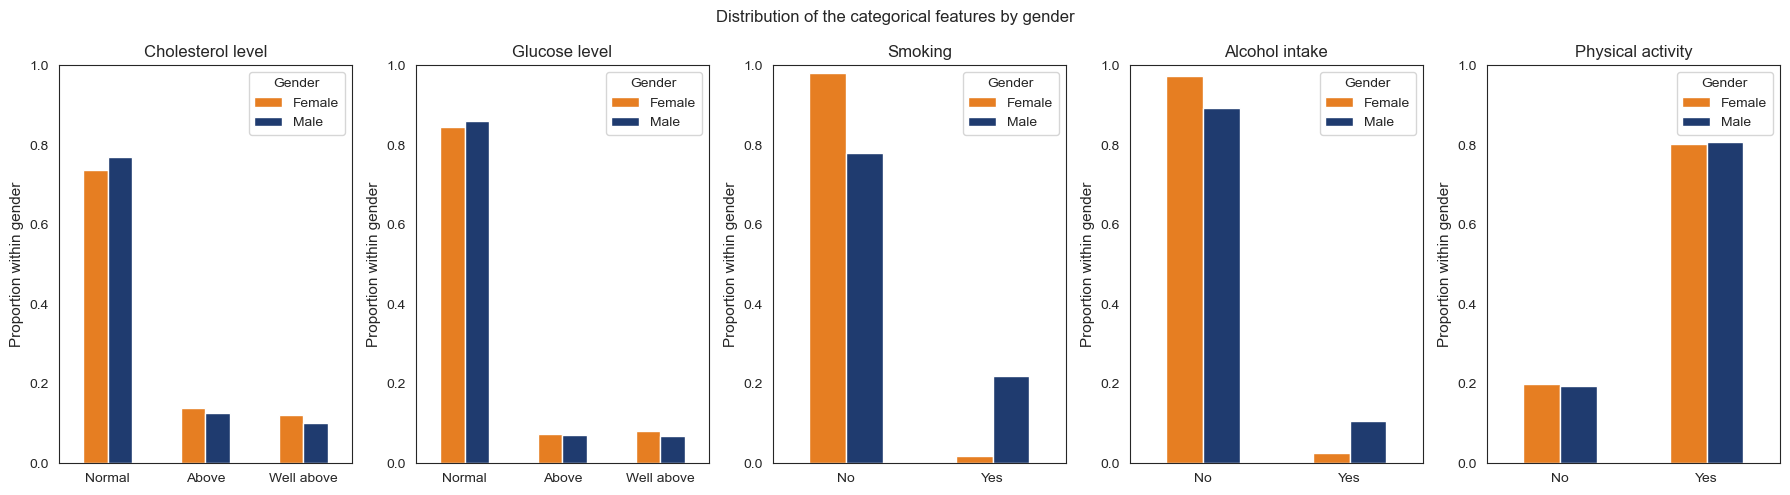

Proportion of cholesterol within each gender:
gender              1         2
cholesterol                    
1            0.738523  0.771121
2            0.139918  0.127267
3            0.121559  0.101613

Proportion of gluc within each gender:
gender         1         2
gluc                      
1       0.845278  0.859447
2       0.074823  0.071906
3       0.079899  0.068647

Proportion of smoke within each gender:
gender         1         2
smoke                     
0       0.982267  0.780856
1       0.017733  0.219144

Proportion of alco within each gender:
gender         1         2
alco                      
0       0.974798  0.894042
1       0.025202  0.105958

Proportion of active within each gender:
gender        1         2
active                   
0       0.19835  0.193407
1       0.80165  0.806593



In [22]:
# Compare the categorical features between male and female patients
# For each feature the proportion in each category is calculated within each gender, so the bars show how the distribution differs between men and women
categorical_cols = ['cholesterol', 'gluc', 'smoke', 'alco', 'active']
categorical_labels = {'cholesterol': 'Cholesterol level', 'gluc': 'Glucose level', 'smoke': 'Smoking', 'alco': 'Alcohol intake', 'active': 'Physical activity'}
value_labels = {'cholesterol': {1: 'Normal', 2: 'Above', 3: 'Well above'}, 'gluc': {1: 'Normal', 2: 'Above', 3: 'Well above'}, 'smoke': {0: 'No', 1: 'Yes'}, 'alco': {0: 'No', 1: 'Yes'}, 'active': {0: 'No', 1: 'Yes'}}
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
for i, col in enumerate(categorical_cols):

    # The proportion of each category within each gender, so the two genders can be compared directly
    gender_distribution = pd.crosstab(df[col], df['gender'], normalize='columns')
    gender_distribution.plot(kind='bar', ax=axes[i], color=['#e67e22', '#1f3b6f'])
    axes[i].set_title(categorical_labels[col])
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Proportion within gender')
    axes[i].set_ylim(0, 1)
    
    # Replace the numeric category codes with readable labels
    readable_ticks = []
    for code in gender_distribution.index:
        readable_ticks.append(value_labels[col][code])
    axes[i].set_xticklabels(readable_ticks, rotation=0)
    axes[i].legend(['Female', 'Male'], title='Gender')
    
plt.suptitle('Distribution of the categorical features by gender')
plt.tight_layout()
plt.show()

# Print the exact proportion of each category within each gender to support the charts
for col in categorical_cols:
    print('Proportion of {} within each gender:\n{}\n'.format(col, pd.crosstab(df[col], df['gender'], normalize='columns')))

The categorical features are distributed quite differently between the genders, especially for smoking and alcohol intake. Among male patients about 21.9% smoke, compared with only 1.8% of female patients, and alcohol intake is also far more common in men (10.6% versus 2.5%). Cholesterol, glucose and physical activity, in contrast, are distributed much more similarly across the two genders. These differences show that some of the categorical features carry gender information as well, which matters because a model could rely on them differently for male and female patients. The next chart looks at how these same categories relate to cardiovascular disease itself.

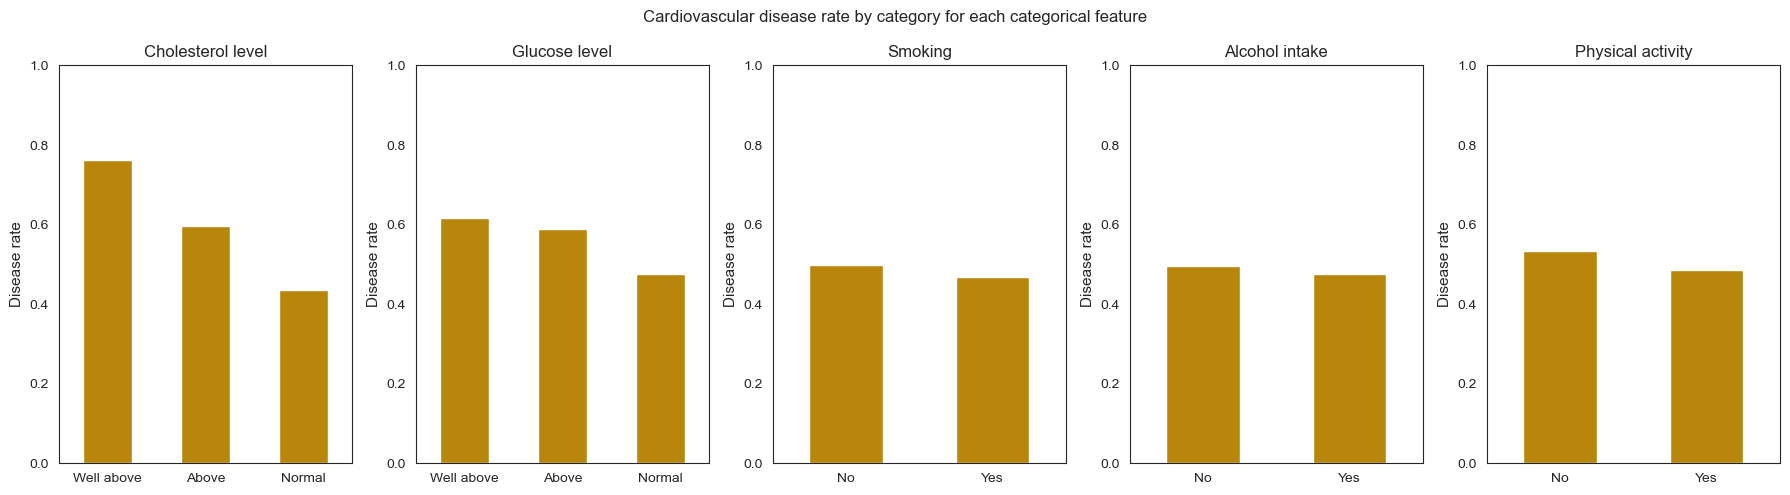

Disease rate by cholesterol:
cholesterol
3    0.762583
2    0.596367
1    0.435434
Name: target, dtype: float64

Disease rate by gluc:
gluc
3    0.617523
2    0.588711
1    0.475604
Name: target, dtype: float64

Disease rate by smoke:
smoke
0    0.497277
1    0.468367
Name: target, dtype: float64

Disease rate by alco:
alco
0    0.495769
1    0.476385
Name: target, dtype: float64

Disease rate by active:
active
0    0.532780
1    0.485423
Name: target, dtype: float64



In [23]:
# Look at the five categorical features and the disease rate within each category
# This shows whether some categories are linked to a much higher chance of cardiovascular disease
categorical_cols = ['cholesterol', 'gluc', 'smoke', 'alco', 'active']

# Readable titles for each categorical feature
categorical_labels = {'cholesterol': 'Cholesterol level', 'gluc': 'Glucose level', 'smoke': 'Smoking', 'alco': 'Alcohol intake', 'active': 'Physical activity'}
value_labels = {'cholesterol': {1: 'Normal', 2: 'Above', 3: 'Well above'}, 'gluc': {1: 'Normal', 2: 'Above', 3: 'Well above'}, 'smoke': {0: 'No', 1: 'Yes'}, 'alco': {0: 'No', 1: 'Yes'}, 'active': {0: 'No', 1: 'Yes'}}
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
for i, col in enumerate(categorical_cols):

    # The disease rate within each category, sorted so the highest-risk category is first
    disease_rate = df.groupby(col)['target'].mean().sort_values(ascending=False)
    disease_rate.plot(kind='bar', ax=axes[i], color='#b8860b')
    axes[i].set_title(categorical_labels[col])
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Disease rate')
    axes[i].set_ylim(0, 1)
    
    # Replace the numeric category codes with readable labels
    readable_ticks = []
    for code in disease_rate.index:
        readable_ticks.append(value_labels[col][code])
    axes[i].set_xticklabels(readable_ticks, rotation=0)

plt.suptitle('Cardiovascular disease rate by category for each categorical feature')
plt.tight_layout()
plt.show()

# Print the exact disease rate within each category to support the charts
for col in categorical_cols:
    print('Disease rate by {}:\n{}\n'.format(col, df.groupby(col)['target'].mean().sort_values(ascending=False)))

The disease rate differs sharply between categories for some features but not others. Cholesterol is the most striking: patients with well above normal cholesterol have a disease rate of about 76.3%, compared with only 43.5% for those with normal levels. Glucose follows a similar but weaker pattern. Smoking, alcohol intake and physical activity, by contrast, barely change the disease rate at all, even though smoking and alcohol differed strongly between the genders. This means that the features which separate the genders are not the same as the ones that predict disease, which is an important distinction for the fairness analysis. The strong patterns in cholesterol and glucose can later be compared against the SHAP results to see whether the models rely on the same features.

## 3. Data Preprocessing

Before modelling, the data is prepared for the machine learning models. The biologically implausible values were already removed during exploration, so the data is clean at this stage and there are no missing values to impute. The gender column is recoded to a simple binary form, the features are separated from the target, and the data is then split into training and test sets before any scaling, so that information from the test set never leaks into training. The features are finally scaled to a common range.

### Recode the gender column

The `gender` column is recoded from 1 and 2 to 0 and 1, so that it is a simple binary feature with 0 representing female and 1 representing male. This is the sensitive attribute used in the fairness analysis. The other categorical features are already numeric and ordered, so they are left as they are.

In [24]:
# Convert the gender column from 1 and 2 to integer codes for machine learning
# Gender is shown before and after conversion to verify the mapping, since it is the sensitive attribute
print('Gender is originally coded as 1 and 2:\n{}'.format(df['gender'].value_counts()))
df['gender'] = df['gender'].astype('category').cat.codes
print('\nGender is converted to integer (0 = female, 1 = male):\n{}'.format(df['gender'].value_counts()))

# The other categorical features are already numeric and are left unchanged, so their codes are stated here for reference
print('\nCategory codes for the remaining categorical features:')
print('cholesterol codes: {1: normal, 2: above normal, 3: well above normal}')
print('gluc codes: {1: normal, 2: above normal, 3: well above normal}')
print('smoke codes: {0: no, 1: yes}')
print('alco codes: {0: no, 1: yes}')
print('active codes: {0: no, 1: yes}')

Gender is originally coded as 1 and 2:
gender
1    44719
2    23934
Name: count, dtype: int64

Gender is converted to integer (0 = female, 1 = male):
gender
0    44719
1    23934
Name: count, dtype: int64

Category codes for the remaining categorical features:
cholesterol codes: {1: normal, 2: above normal, 3: well above normal}
gluc codes: {1: normal, 2: above normal, 3: well above normal}
smoke codes: {0: no, 1: yes}
alco codes: {0: no, 1: yes}
active codes: {0: no, 1: yes}


### Separate the features and the target

The data is split into the feature matrix `X` and the target vector `y`. Two columns are removed from `X`: `target` (the variable being predicted) and `cardio` (the original column that `target` was copied from, which would leak the answer). All the other columns are kept as features, since they are genuine clinical measurements.

In [25]:
# Separate the features from the target
# target is the label and cardio is the original column it was copied from, so both are removed from the features
X = df.drop(['target', 'cardio'], axis=1)
y = df['target']

# Confirm the feature columns that will go into the models
print('Feature columns:\n{}'.format(X.columns.tolist()))
print('\nShape of X: {}, shape of y: {}'.format(X.shape, y.shape))
X.head()

Feature columns:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

Shape of X: (68653, 11), shape of y: (68653,)


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active
0,50.391781,1,168,62.0,110,80,1,1,0,0,1
1,55.419178,0,156,85.0,140,90,3,1,0,0,1
2,51.663014,0,165,64.0,130,70,3,1,0,0,0
3,48.282192,1,169,82.0,150,100,1,1,0,0,1
4,47.873973,0,156,56.0,100,60,1,1,0,0,0


### Split into training and test sets

The data is split into a training set and a test set before any scaling or resampling, so that no information from the test set leaks into the preparation of the training data. A test size of 20% is used, and the split is stratified by the target so that the proportion of patients with and without cardiovascular disease is the same in both sets. The random state is fixed so that the split is reproducible.

In [26]:
# Import the train/test split function
from sklearn.model_selection import train_test_split

# Split into training and test sets before any scaling or resampling to avoid leakage
# stratify=y keeps the same disease rate in both sets, and the random state makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=random_state)

# Confirm the sizes and that the disease rate is preserved in both sets
print('Training set: {} patients'.format(X_train.shape[0]))
print('Test set: {} patients'.format(X_test.shape[0]))
print('\nDisease rate in training set:\n{}'.format(y_train.value_counts(normalize=True)))
print('\nDisease rate in test set:\n{}'.format(y_test.value_counts(normalize=True)))

Training set: 54922 patients
Test set: 13731 patients

Disease rate in training set:
target
0    0.505262
1    0.494738
Name: proportion, dtype: float64

Disease rate in test set:
target
0    0.50528
1    0.49472
Name: proportion, dtype: float64


### Scale the features

The features are scaled to a 0 to 1 range using MinMaxScaler so that variables with larger ranges (such as blood pressure) do not dominate variables with smaller ranges (such as the categorical features). This mainly matters for Logistic Regression; tree based models are not affected by scaling, but the same scaled data is used for all models for consistency. The scaler is fitted only on the training set and then applied to the test set, so that no information from the test set leaks into the scaling.

In [27]:
# Import the scaler
from sklearn.preprocessing import MinMaxScaler

# Scale features to a 0-1 range so that variables with larger ranges do not dominate the learning process
# The scaler is fitted only on the training set to avoid leaking information from the test set
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Confirm the scaling worked by checking the min and max of the training features
print('Minimum of scaled training features: {}'.format(X_train.min()))
print('Maximum of scaled training features: {}'.format(X_train.max()))

Minimum of scaled training features: 0.0
Maximum of scaled training features: 1.0


## 4. Feature Selection

Before training the models, the features are checked to decide whether any of them should be removed. This is done in two steps. First the correlation between every pair of features is examined to look for multicollinearity, which is when two features carry almost the same information so that one of them adds little. Then the strength of association between each feature and the target is checked using several scoring methods. The more detailed feature importance that is central to this project, including the comparison between male and female patients, is left to the SHAP analysis later on, which is better suited to that purpose.

### Multicollinearity between features

The correlation between every pair of features is examined first. If two features were very strongly correlated they would carry almost the same information, so one of them could be removed without losing much. The scaled training features are used here, and because correlation is not affected by scaling the values are the same as on the original data.

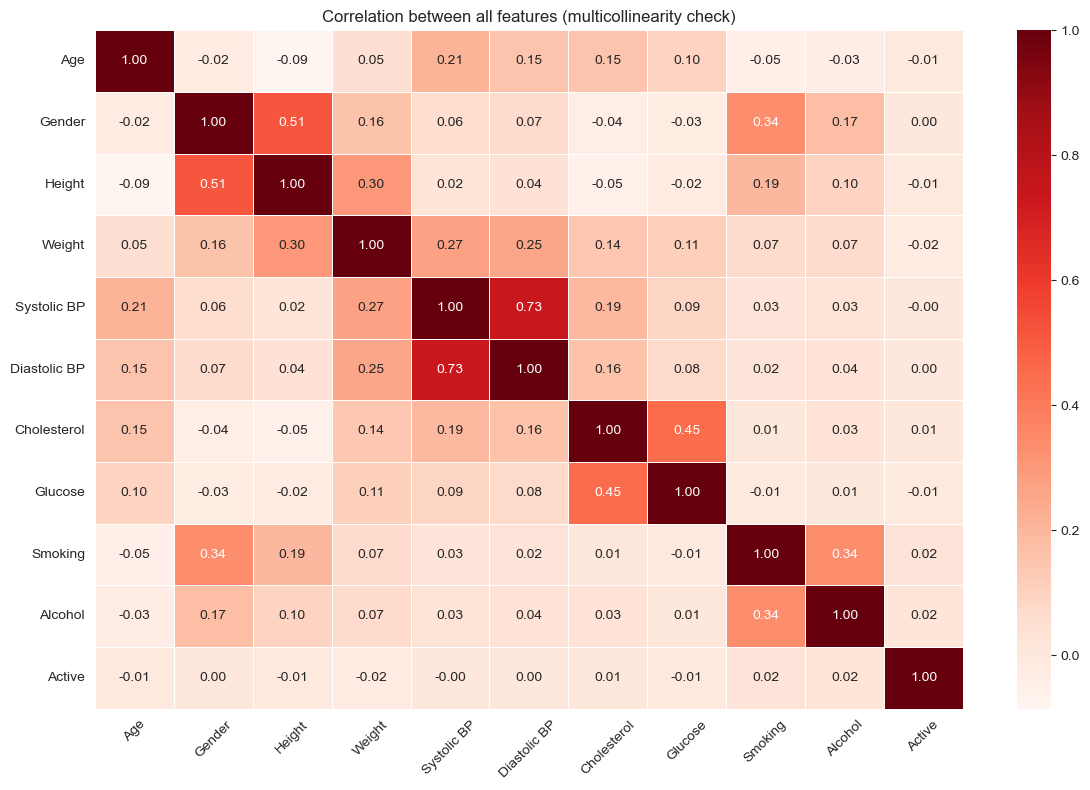

Correlation of each feature with the target:
target         1.000000
ap_hi          0.428166
ap_lo          0.339106
age            0.233850
cholesterol    0.222421
weight         0.183549
gluc           0.089622
gender         0.005155
alco          -0.008276
height        -0.010804
smoke         -0.017991
active        -0.038610
Name: target, dtype: float64

Correlation between features:
                  age    gender    height    weight     ap_hi     ap_lo  \
age          1.000000 -0.021395 -0.085890  0.052514  0.208291  0.153563   
gender      -0.021395  1.000000  0.512558  0.156343  0.061562  0.066546   
height      -0.085890  0.512558  1.000000  0.302020  0.020528  0.038042   
weight       0.052514  0.156343  0.302020  1.000000  0.272042  0.254704   
ap_hi        0.208291  0.061562  0.020528  0.272042  1.000000  0.733906   
ap_lo        0.153563  0.066546  0.038042  0.254704  0.733906  1.000000   
cholesterol  0.152474 -0.038269 -0.053705  0.142001  0.193412  0.161492   
gluc   

In [28]:
# Look at the correlation between every pair of features to check for multicollinearity
# A heatmap makes it easy to see whether any two features carry almost the same information
# The scaled training data is wrapped back into a DataFrame so the feature names are available
X_train_df = pd.DataFrame(X_train, columns=X.columns)
corr = X_train_df.corr()

# Use short readable labels so the heatmap stays clear, matching the labels used in the earlier heatmaps
corr_labels = ['Age', 'Gender', 'Height', 'Weight', 'Systolic BP', 'Diastolic BP', 'Cholesterol', 'Glucose', 'Smoking', 'Alcohol', 'Active']
corr.index = corr_labels
corr.columns = corr_labels

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='Reds', fmt='.2f', linewidths=0.5)
plt.title('Correlation between all features (multicollinearity check)')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print the correlation of each feature with the target, sorted, to show which features are most related to cardiovascular disease
X_train_with_target = X_train_df.copy()
X_train_with_target['target'] = y_train.values
print('Correlation of each feature with the target:\n{}'.format(X_train_with_target.corr()['target'].sort_values(ascending=False)))

# Print the correlations between the features to check that no pair is too highly correlated
print('\nCorrelation between features:\n{}'.format(X_train_df.corr()))

The heatmap and the correlation table show that no pair of features is strongly correlated. The strongest correlation between any two different features is only 0.73 (between systolic and diastolic blood pressure), which is below the common threshold of 0.85 that would suggest two features carry redundant information. The two are measured together so some correlation is expected, but it is not high enough to be a problem. There is therefore no multicollinearity problem and no feature needs to be removed for this reason. The correlation with the target also gives an early indication of which features matter most: systolic blood pressure (0.43), diastolic blood pressure (0.34), age (0.23), cholesterol (0.22) and weight (0.18) show the strongest relationships, while gender, height and the lifestyle features are very weakly related. This is only a first look using simple pairwise correlation, and the importance of each feature is examined more carefully in the next step.

### Univariate feature importance

The strength of the relationship between each feature and the target is now checked using four different scoring methods: chi-squared, the ANOVA F-test, mutual information and the feature importances from an Extra Trees model. Using several methods gives more confidence than relying on a single one, since no single method works best on every dataset. If all four methods agreed that the same feature was clearly the weakest, that feature would be a candidate for removal. The scaled training data is used so that chi-squared, which requires non-negative values, can be applied alongside the other methods.

In [29]:
# Import the feature selection tools and the Extra Trees model
from sklearn.feature_selection import SelectKBest, chi2, f_classif, mutual_info_classif
from sklearn.ensemble import ExtraTreesClassifier

# Wrap the scaled training data into a DataFrame so the feature names can be used as labels
X_train_df = pd.DataFrame(X_train, columns=X.columns)

# Map the short column names to readable labels so the plots are clear, matching the labels used in the heatmaps
readable_labels = {'age': 'Age', 'gender': 'Gender', 'height': 'Height', 'weight': 'Weight', 'ap_hi': 'Systolic BP', 'ap_lo': 'Diastolic BP', 'cholesterol': 'Cholesterol', 'gluc': 'Glucose', 'smoke': 'Smoking', 'alco': 'Alcohol', 'active': 'Active'}

# Score the features with chi-squared, which needs non-negative values, so the scaled 0-1 data is used
chi2_test = SelectKBest(score_func=chi2, k='all').fit(X_train_df, y_train)
chi2_sorted = pd.Series(data=chi2_test.scores_, index=X.columns).sort_values()

# Repeat with the ANOVA F-test scoring function
ftest = SelectKBest(score_func=f_classif, k='all').fit(X_train_df, y_train)
ftest_sorted = pd.Series(data=ftest.scores_, index=X.columns).sort_values()

# Repeat with mutual information, with a fixed random state so the scores are reproducible
mi_scores = mutual_info_classif(X_train_df, y_train, random_state=random_state)
mitest_sorted = pd.Series(data=mi_scores, index=X.columns).sort_values()

# Use an Extra Trees model as an alternative method that scores feature importance while learning to predict
xtrees = ExtraTreesClassifier(random_state=random_state).fit(X_train_df, y_train)
xtrees_sorted = pd.Series(data=xtrees.feature_importances_, index=X.columns).sort_values()

# Print the lowest scoring feature for each method to see whether they agree on a weak feature
print('Lowest scoring feature by chi2: {}'.format(chi2_sorted.index[0]))
print('Lowest scoring feature by F-test: {}'.format(ftest_sorted.index[0]))
print('Lowest scoring feature by MI: {}'.format(mitest_sorted.index[0]))
print('Lowest scoring feature by ExtraTrees: {}'.format(xtrees_sorted.index[0]))

Lowest scoring feature by chi2: height
Lowest scoring feature by F-test: gender
Lowest scoring feature by MI: gluc
Lowest scoring feature by ExtraTrees: alco


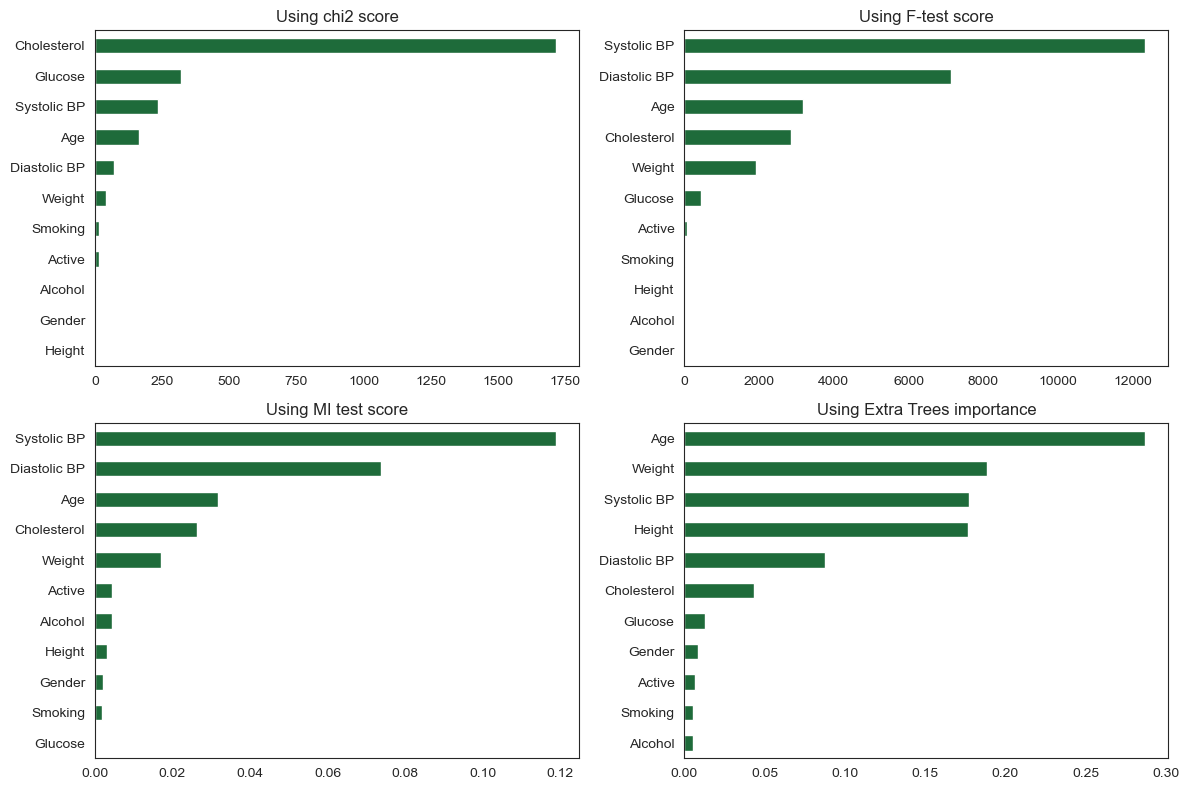

In [30]:
# Rename the index of each result to readable labels so the plots show full feature names
chi2_sorted = chi2_sorted.rename(index=readable_labels)
ftest_sorted = ftest_sorted.rename(index=readable_labels)
mitest_sorted = mitest_sorted.rename(index=readable_labels)
xtrees_sorted = xtrees_sorted.rename(index=readable_labels)

# Plot the feature selection scores from all four methods side by side so the rankings can be compared
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
plt.subplots_adjust(wspace=0.6)
chi2_sorted.plot(kind='barh', ax=axes[0, 0], title='Using chi2 score', color='#1e6b3a')
ftest_sorted.plot(kind='barh', ax=axes[0, 1], title='Using F-test score', color='#1e6b3a')
mitest_sorted.plot(kind='barh', ax=axes[1, 0], title='Using MI test score', color='#1e6b3a')
xtrees_sorted.plot(kind='barh', ax=axes[1, 1], title='Using Extra Trees importance', color='#1e6b3a')
plt.tight_layout()
plt.show()

The four methods do not agree on a single weakest feature. Chi-squared ranks height lowest, the F-test ranks gender lowest, mutual information ranks glucose lowest, and the Extra Trees model ranks alcohol lowest. Because no feature is consistently ranked as the weakest across all four methods, there is no clear candidate for removal, so all eleven features are kept for modelling. This matches what would be expected for this dataset, since every feature is a recognised clinical or lifestyle measurement rather than an arbitrary variable. 

These scoring methods are only a first check, because each one looks at a single feature in isolation and ignores how features interact and which direction they push a prediction. The more detailed feature importance that matters most for this project is produced later by SHAP, which works from the trained models themselves, shows whether each feature pushes a prediction towards or away from disease, and can be split by sex to compare how the models rely on each feature for male and female patients. The simple ranking here is therefore kept as background, while the SHAP analysis carries the main weight of the importance and fairness discussion.

## 5. Model Training and Evaluation

Three classification models are trained and compared: Logistic Regression as a linear baseline, Random Forest as a tree-based ensemble, and XGBoost as a gradient boosting method. Each model is evaluated using 5-fold cross-validation on the training set and a range of metrics on the held-out test set: accuracy, precision, recall, F1-score and AUC-ROC. A confusion matrix is also produced for each model. The same training and test split prepared earlier is used for all three models so that the comparison is fair.

In [31]:
# Import the three classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Import cross-validation and the evaluation metrics
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix

In [32]:
def train_and_evaluate(model, X_train, X_test, y_train, y_test):
    """
    Train and evaluate a classification model using cross-validation on the
    training data and a range of metrics on the separate test set, and display a confusion matrix.
    """
    print('\nResults from algorithm {}:'.format(model))
    
    # Cross-validation accuracy gives an indication of how much the accuracy varies
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    print('Mean cross-validation accuracy is {:.4f} with SD {:.4f}'
          .format(np.mean(scores), np.std(scores)))

    # Fit the model using all of the training data
    learnt_model = model.fit(X_train, y_train)
    print('\nAccuracy on training data is {:.4f}\n'.format(model.score(X_train, y_train)))

    # Use predict() to predict the target values for the test set
    y_pred = model.predict(X_test)

    # Use predict_proba() to get the probability of disease for the AUC-ROC score
    y_proba = model.predict_proba(X_test)[:, 1]

    # Print the test metrics, including AUC-ROC which is not threshold dependent
    print('Test data metrics: accuracy={:.4f}, f1={:.4f}, precision={:.4f}, recall={:.4f}, auc={:.4f}'
          .format(accuracy_score(y_true=y_test, y_pred=y_pred),
                  f1_score(y_true=y_test, y_pred=y_pred),
                  precision_score(y_true=y_test, y_pred=y_pred),
                  recall_score(y_true=y_test, y_pred=y_pred),
                  roc_auc_score(y_true=y_test, y_score=y_proba)))

    # Draw out a confusion matrix
    cm = confusion_matrix(y_true=y_test, y_pred=y_pred)
    plt.figure(figsize=(3, 3))
    ax = sns.heatmap(cm, annot=True, fmt='d', cmap='OrRd', cbar=False, xticklabels=['0', '1'],
                     yticklabels=['0', '1'], square=True, linewidths=8.0)
    ax.set_xlabel('Predicted disease')
    ax.set_ylabel('Actual disease')
    plt.tight_layout()
    plt.show()
    return learnt_model

### Logistic Regression

Logistic Regression is trained first as a linear baseline. It is a simple and interpretable model that draws a linear decision boundary, so it provides a useful reference point against which the more complex tree-based models can be compared. The maximum number of iterations is increased to 200 so that the solver has enough steps to converge.


Results from algorithm LogisticRegression(max_iter=200):
Mean cross-validation accuracy is 0.7287 with SD 0.0039

Accuracy on training data is 0.7290

Test data metrics: accuracy=0.7212, f1=0.7002, precision=0.7480, recall=0.6582, auc=0.7903


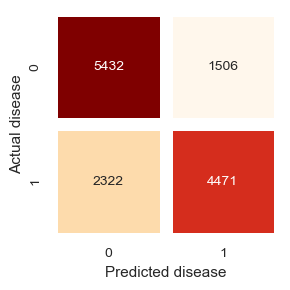

In [33]:
# Train and evaluate Logistic Regression as the linear baseline
log_reg = train_and_evaluate(LogisticRegression(max_iter=200), X_train, X_test, y_train, y_test)

### Random Forest

Random Forest is trained next as a tree-based ensemble model. Instead of fitting a single decision tree, it builds many trees on random subsets of the data and features and averages their predictions, which usually gives better performance and reduces overfitting compared with a single tree. It can also capture non-linear patterns that the linear Logistic Regression baseline cannot. The random state is fixed so that the results are reproducible.


Results from algorithm RandomForestClassifier(random_state=42):
Mean cross-validation accuracy is 0.7135 with SD 0.0046

Accuracy on training data is 0.9998

Test data metrics: accuracy=0.7123, f1=0.7041, precision=0.7166, recall=0.6920, auc=0.7717


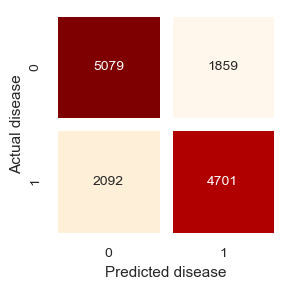

In [34]:
# Train and evaluate Random Forest as a tree-based ensemble model
rf = train_and_evaluate(RandomForestClassifier(random_state=random_state), X_train, X_test, y_train, y_test)

### XGBoost

XGBoost is the third model, a gradient boosting method that builds trees sequentially, where each new tree tries to correct the errors made by the previous ones. This often gives strong predictive performance on structured data and provides another non-linear model to compare against Random Forest. The random state is fixed for reproducibility, and the evaluation metric is set to log loss, which is the standard objective for binary classification.


Results from algorithm XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...):
Mean cross-validation accuracy is 0.7301 with SD 0.0027

Accuracy on training data is 0.7650

Test data metrics: accuracy=0.7240, f1=0.7078, precision=0.7430, recall=0.6758, auc=0.7926


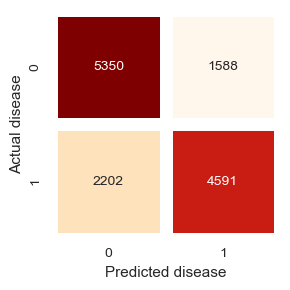

In [35]:
# Train and evaluate XGBoost as a gradient boosting model
xgb = train_and_evaluate(XGBClassifier(random_state=random_state, eval_metric='logloss'), X_train, X_test, y_train, y_test)

### Model comparison

The three default models are compared side by side using the test set metrics, together with the training accuracy to check for overfitting. This summary makes it easier to see which model performs best before any hyperparameter tuning is applied.

In [36]:
# Get the predictions and predicted probabilities for each model on the test set
log_reg_pred = log_reg.predict(X_test)
log_reg_proba = log_reg.predict_proba(X_test)[:, 1]
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]
xgb_pred = xgb.predict(X_test)
xgb_proba = xgb.predict_proba(X_test)[:, 1]

# Build a comparison table with the training accuracy and the test metrics for all three models
comparison = pd.DataFrame({
    'Logistic Regression': [log_reg.score(X_train, y_train),
                            accuracy_score(y_true=y_test, y_pred=log_reg_pred),
                            f1_score(y_true=y_test, y_pred=log_reg_pred),
                            precision_score(y_true=y_test, y_pred=log_reg_pred),
                            recall_score(y_true=y_test, y_pred=log_reg_pred),
                            roc_auc_score(y_true=y_test, y_score=log_reg_proba)],
    'Random Forest': [rf.score(X_train, y_train),
                      accuracy_score(y_true=y_test, y_pred=rf_pred),
                      f1_score(y_true=y_test, y_pred=rf_pred),
                      precision_score(y_true=y_test, y_pred=rf_pred),
                      recall_score(y_true=y_test, y_pred=rf_pred),
                      roc_auc_score(y_true=y_test, y_score=rf_proba)],
    'XGBoost': [xgb.score(X_train, y_train),
                accuracy_score(y_true=y_test, y_pred=xgb_pred),
                f1_score(y_true=y_test, y_pred=xgb_pred),
                precision_score(y_true=y_test, y_pred=xgb_pred),
                recall_score(y_true=y_test, y_pred=xgb_pred),
                roc_auc_score(y_true=y_test, y_score=xgb_proba)]
}, index=['Training accuracy', 'Test accuracy', 'F1 score', 'Precision', 'Recall', 'AUC-ROC'])

# Show the comparison rounded to four decimals for readability
print('Model comparison on the test set:\n{}'.format(comparison.round(4)))

Model comparison on the test set:
                   Logistic Regression  Random Forest  XGBoost
Training accuracy               0.7290         0.9998   0.7650
Test accuracy                   0.7212         0.7123   0.7240
F1 score                        0.7002         0.7041   0.7078
Precision                       0.7480         0.7166   0.7430
Recall                          0.6582         0.6920   0.6758
AUC-ROC                         0.7903         0.7717   0.7926


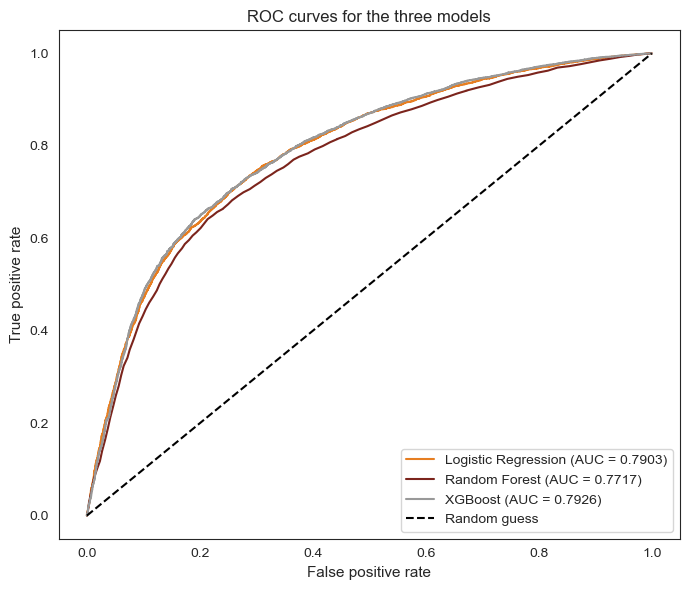

In [37]:
# Plot the ROC curve for all three models on the same axes to compare them visually
# The ROC curve shows the trade-off between the true positive rate and the false positive rate, and the area under it is the AUC reported in the table above
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))
# For each model, compute the false positive rate and true positive rate across thresholds, then plot the curve
log_reg_fpr, log_reg_tpr, _ = roc_curve(y_test, log_reg_proba)
plt.plot(log_reg_fpr, log_reg_tpr, label='Logistic Regression (AUC = {:.4f})'.format(roc_auc_score(y_test, log_reg_proba)), color='#e67e22')
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_proba)
plt.plot(rf_fpr, rf_tpr, label='Random Forest (AUC = {:.4f})'.format(roc_auc_score(y_test, rf_proba)), color='#7b241c')
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_proba)
plt.plot(xgb_fpr, xgb_tpr, label='XGBoost (AUC = {:.4f})'.format(roc_auc_score(y_test, xgb_proba)), color='#999999')

# Add the diagonal line that represents a model with no predictive ability (random guessing)
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random guess')
plt.title('ROC curves for the three models')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

The comparison shows that the three models perform very similarly on the test set, with only small differences between them. XGBoost achieves the highest test accuracy (0.7240), F1 score (0.7078) and AUC-ROC (0.7926), which means it makes slightly the most correct predictions overall and separates the two classes a little better across all thresholds. Logistic Regression has the highest precision (0.7480), so when it predicts disease it is right slightly more often, while Random Forest has the highest recall (0.6920), meaning it catches a few more of the patients who actually have the disease. The ROC curves above show this visually: all three models sit well above the diagonal random-guess line and their curves are very close together, which reflects how similar their performance is. The confusion matrices make this concrete. Out of the 6793 patients who actually have the disease in the test set, Random Forest misses 2092 (false negatives), compared with 2202 for XGBoost and 2322 for Logistic Regression, so Random Forest makes the fewest missed diagnoses, while Logistic Regression raises the fewest false alarms (1506 false positives), which matches its higher precision. In a clinical setting a false negative, missing a patient who actually has the disease, is usually more serious than a false alarm, which is why recall and the false negative count matter most here.

A key observation is the difference between training and test accuracy. Logistic Regression has a training accuracy of 0.7290 and a test accuracy of 0.7212, which are very close, so it is not overfitting. XGBoost is similar, with a training accuracy of 0.7650 and a test accuracy of 0.7240, so it is also not overfitting in any serious way. Random Forest, in contrast, reaches a training accuracy of 0.9998, meaning it classifies almost every single training patient correctly, while its test accuracy is only 0.7123. When a model is almost perfect on the training data but noticeably lower on the test data, it has memorised the training examples rather than learning general patterns, which is called overfitting. This happens because the trees in the Random Forest are allowed to grow until they fit the training data exactly.

However, this overfitting does not make the model unusable. Its test performance is still reasonable (around 0.71), and its cross-validation scores are stable: Random Forest has a mean cross-validation accuracy of 0.7135 with a very low standard deviation of 0.0046, which means it performs consistently across different subsets of the training data rather than depending on one lucky split. This consistency suggests the model still performs reasonably well on unseen patients despite the perfect training score. The gap between training and test accuracy will be addressed in the next section through hyperparameter tuning, which limits how complex the model can become in order to reduce overfitting while keeping the predictive performance.

## 6. Hyperparameter Tuning

The model comparison above showed that Random Forest reaches a perfect training accuracy of 0.9998, which is a sign of overfitting. In this section the hyperparameters of each model are tuned to reduce this overfitting while keeping the predictive performance. A helper function trains a model with a given set of hyperparameters and returns its mean cross-validation accuracy, so that a range of values can be compared. The best value for each hyperparameter is chosen using cross-validation on the training set only, and the tuned models are then evaluated on the held-out test set. The test set is never used to choose the hyperparameters.

In [38]:
# Helper function that trains a model with a given set of hyperparameters and returns its mean cross-validation accuracy
# This is used to compare a range of hyperparameter values during tuning
def train_model(algorithm, hyperparams, X, y):
    """
    Use cross-validation to determine the model accuracy for a given algorithm and set of hyperparameters,
    and return the mean accuracy across the folds together with the trained model.
    """
    model = algorithm(**hyperparams)
    scores = cross_val_score(model, X, y, cv=10, scoring='accuracy')
    learnt_model = model.fit(X, y)
    return (np.mean(scores), learnt_model)

### Tuning Logistic Regression

For Logistic Regression the main hyperparameter is `C`, the inverse of the regularisation strength. A small `C` applies strong regularisation, which keeps the model simple and can prevent overfitting, while a large `C` lets the model fit the training data more closely. A range of values is tried and the mean cross-validation accuracy is recorded for each, so that the value which generalises best can be chosen. The maximum number of iterations is kept at 200 so that the solver converges.

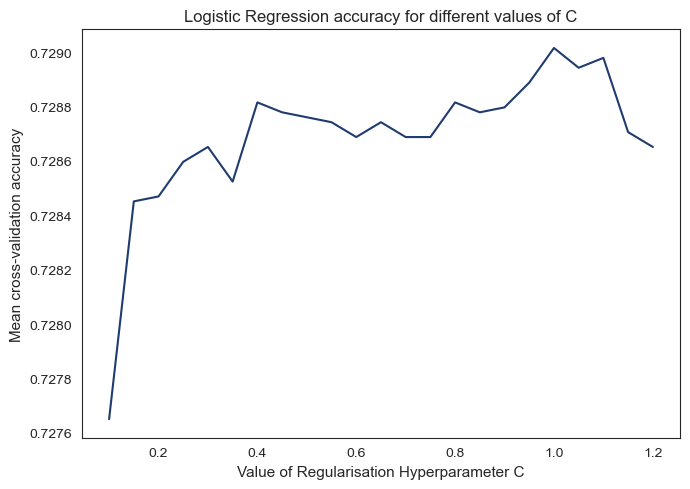

Best C value: 1.00 with cross-validation accuracy 0.7290


In [39]:
# Try a range of regularisation strengths C for Logistic Regression
# A smaller C means stronger regularisation, and the cross-validation accuracy is recorded for each value
reg_values = [0.05 * i for i in range(2, 25)]
reg_accuracy = []
for reg_strength in reg_values:
    acc, _ = train_model(LogisticRegression, {'C': reg_strength, 'max_iter': 200}, X_train, y_train)
    reg_accuracy.append(acc)

# Plot the cross-validation accuracy against the value of C to see which gives the best result
plt.figure(figsize=(7, 5))
plt.plot(reg_values, reg_accuracy, color='#1f3b6f')
plt.title('Logistic Regression accuracy for different values of C')
plt.ylabel('Mean cross-validation accuracy')
plt.xlabel('Value of Regularisation Hyperparameter C')
plt.tight_layout()
plt.show()

# Find and report the C value that gives the highest cross-validation accuracy
best_C = reg_values[np.argmax(reg_accuracy)]
print('Best C value: {:.2f} with cross-validation accuracy {:.4f}'.format(best_C, np.max(reg_accuracy)))

### Tuning Random Forest

Random Forest overfitted on the default settings, reaching a perfect training accuracy of 0.9998. Two hyperparameters are used together to control this. The first is `max_depth`, which limits how deep each tree in the forest can grow, and a range of depth values is tried so that the depth which generalises best can be chosen. The second is `min_samples_leaf`, which is fixed at 5 so that every leaf must contain at least five patients rather than being allowed to split down to a single patient, which is the default behaviour that lets the trees fit the training data exactly. The mean cross-validation accuracy is recorded for each depth value, and the random state is fixed so that the results are reproducible.

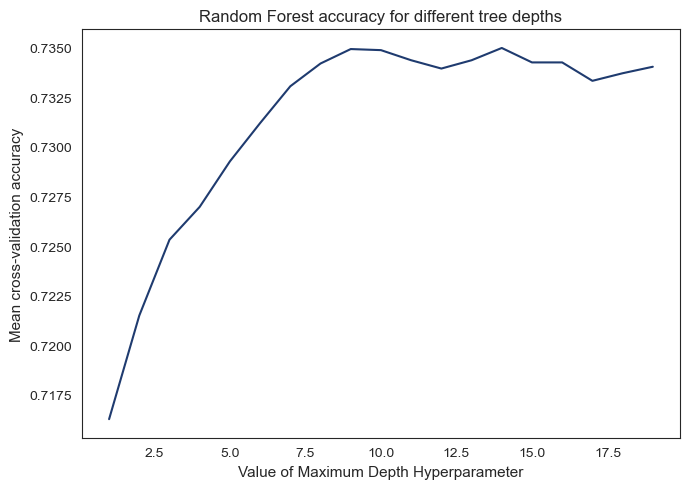

Best max_depth value: 14 with cross-validation accuracy 0.7350


In [40]:
# Try a range of maximum depth values for Random Forest to control overfitting
# A smaller depth keeps the trees simpler, and min_samples_leaf is fixed at 5 so each leaf needs at least five patients, which also reduces overfitting
depth_values = [i for i in range(1, 20)]
depth_accuracy = []
for depth in depth_values:
    acc, _ = train_model(RandomForestClassifier, {'max_depth': depth, 'min_samples_leaf': 5, 'random_state': random_state, 'n_jobs': -1}, X_train, y_train)
    depth_accuracy.append(acc)

# Plot the cross-validation accuracy against the tree depth to see which gives the best result
plt.figure(figsize=(7, 5))
plt.plot(depth_values, depth_accuracy, color='#1f3b6f')
plt.title('Random Forest accuracy for different tree depths')
plt.ylabel('Mean cross-validation accuracy')
plt.xlabel('Value of Maximum Depth Hyperparameter')
plt.tight_layout()
plt.show()

# Find and report the depth value that gives the highest cross-validation accuracy
best_depth = depth_values[np.argmax(depth_accuracy)]
print('Best max_depth value: {} with cross-validation accuracy {:.4f}'.format(best_depth, np.max(depth_accuracy)))

### Tuning XGBoost

XGBoost is retrained with its hyperparameters tuned to control overfitting. Two settings are used together. The `max_depth` is tuned across a range of values to find the depth which generalises best, while the `learning_rate` is fixed at 0.05 with `n_estimators` set to 150, so that the model learns slowly over more trees rather than fitting the training data quickly. A lower learning rate makes each tree contribute a smaller correction, which reduces overfitting. The mean cross-validation accuracy is recorded for each depth value, and the random state is fixed so that the results are reproducible.

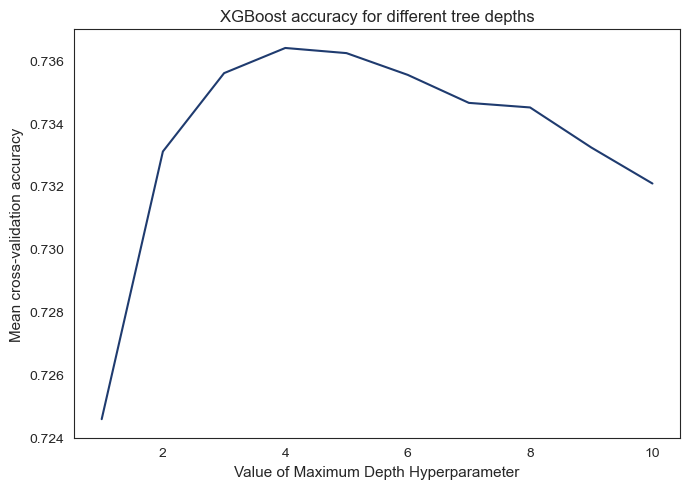

Best max_depth value: 4 with cross-validation accuracy 0.7364


In [41]:
# Try a range of maximum depth values for XGBoost to control overfitting
# A smaller depth keeps the trees simpler, and learning_rate is fixed at 0.05 with 150 trees so the model learns slowly and carefully, which also reduces overfitting
# The cross-validation accuracy is recorded for each value
xgb_depth_values = [i for i in range(1, 11)]
xgb_depth_accuracy = []
for depth in xgb_depth_values:
    acc, _ = train_model(XGBClassifier, {'max_depth': depth, 'learning_rate': 0.05, 'n_estimators': 150, 'random_state': random_state, 'eval_metric': 'logloss'}, X_train, y_train)
    xgb_depth_accuracy.append(acc)

# Plot the cross-validation accuracy against the tree depth to see which gives the best result
plt.figure(figsize=(7, 5))
plt.plot(xgb_depth_values, xgb_depth_accuracy, color='#1f3b6f')
plt.title('XGBoost accuracy for different tree depths')
plt.ylabel('Mean cross-validation accuracy')
plt.xlabel('Value of Maximum Depth Hyperparameter')
plt.tight_layout()
plt.show()

# Find and report the depth value that gives the highest cross-validation accuracy
best_xgb_depth = xgb_depth_values[np.argmax(xgb_depth_accuracy)]
print('Best max_depth value: {} with cross-validation accuracy {:.4f}'.format(best_xgb_depth, np.max(xgb_depth_accuracy)))

### Evaluating the tuned models

Each model is now retrained with its best hyperparameter value found above and evaluated on the test set, using the same `train_and_evaluate` function as for the default models so that the results can be compared directly. The most important thing to check is the training accuracy of Random Forest: if it has dropped from the near-perfect 0.9998 seen earlier, the overfitting has been reduced. Each model is taken with the best value identified in its tuning plot above, and these values are stated for each model below.

### Tuned Logistic Regression

Logistic Regression is retrained with C=1.00, the best regularisation strength found above, to see whether this changes its performance.


Results from algorithm LogisticRegression(max_iter=200):
Mean cross-validation accuracy is 0.7287 with SD 0.0039

Accuracy on training data is 0.7290

Test data metrics: accuracy=0.7212, f1=0.7002, precision=0.7480, recall=0.6582, auc=0.7903


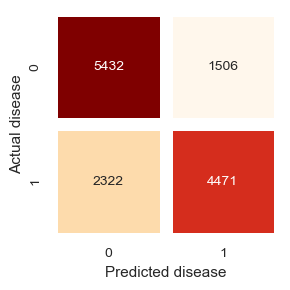

In [42]:
# Retrain Logistic Regression with the best C value and evaluate on the test set
tuned_log_reg = train_and_evaluate(LogisticRegression(C=best_C, max_iter=200), X_train, X_test, y_train, y_test)

### Tuned Random Forest

Random Forest is retrained with max_depth=14, the best depth found above, together with min_samples_leaf fixed at 5, to check whether these limits reduce the overfitting seen in the default model.


Results from algorithm RandomForestClassifier(max_depth=14, min_samples_leaf=5, random_state=42):
Mean cross-validation accuracy is 0.7345 with SD 0.0020

Accuracy on training data is 0.7735

Test data metrics: accuracy=0.7294, f1=0.7132, precision=0.7498, recall=0.6800, auc=0.7979


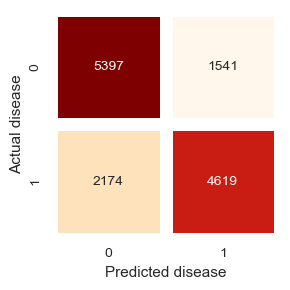

In [43]:
# Retrain Random Forest with the best max_depth value and min_samples_leaf fixed at 5, then evaluate on the test set
tuned_rf = train_and_evaluate(RandomForestClassifier(max_depth=best_depth, min_samples_leaf=5, random_state=random_state), X_train, X_test, y_train, y_test)

### Tuned XGBoost

XGBoost is retrained with max_depth=4, the best depth found above, together with the lower learning_rate of 0.05 and 150 trees, to check whether these settings change the performance seen in the default model.


Results from algorithm XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=150, n_jobs=None,
              num_parallel_tree=None, ...):
Mean cross-validation accuracy is 0.7366 with SD 0.0025

Accuracy on training data is 0.7402

Test data metrics: accuracy=0.7288, f1=0.7122, precision=0.7497, recall=0.6782, auc=0.7991


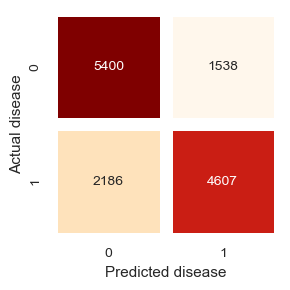

In [44]:
# Retrain XGBoost with the best max_depth value, learning_rate fixed at 0.05 and 150 trees, then evaluate on the test set
tuned_xgb = train_and_evaluate(XGBClassifier(max_depth=best_xgb_depth, learning_rate=0.05, n_estimators=150, random_state=random_state, eval_metric='logloss'), X_train, X_test, y_train, y_test)

### Comparing the default and tuned models

The table below puts the default and tuned versions of each model side by side, so that the effect of the hyperparameter tuning can be seen directly. The training accuracy is included because the main aim of the tuning was to reduce the overfitting seen in the default Random Forest, which reached a near-perfect training accuracy of 0.9998.

In [45]:
# Get the predictions and probabilities for the three tuned models on the test set
tuned_log_reg_pred = tuned_log_reg.predict(X_test)
tuned_log_reg_proba = tuned_log_reg.predict_proba(X_test)[:, 1]
tuned_rf_pred = tuned_rf.predict(X_test)
tuned_rf_proba = tuned_rf.predict_proba(X_test)[:, 1]
tuned_xgb_pred = tuned_xgb.predict(X_test)
tuned_xgb_proba = tuned_xgb.predict_proba(X_test)[:, 1]

# Build a comparison table with the default and tuned version of each model side by side
tuned_comparison = pd.DataFrame({
    'LR default': [log_reg.score(X_train, y_train),
                   accuracy_score(y_true=y_test, y_pred=log_reg_pred),
                   f1_score(y_true=y_test, y_pred=log_reg_pred),
                   precision_score(y_true=y_test, y_pred=log_reg_pred),
                   recall_score(y_true=y_test, y_pred=log_reg_pred),
                   roc_auc_score(y_true=y_test, y_score=log_reg_proba)],
    'LR tuned': [tuned_log_reg.score(X_train, y_train),
                 accuracy_score(y_true=y_test, y_pred=tuned_log_reg_pred),
                 f1_score(y_true=y_test, y_pred=tuned_log_reg_pred),
                 precision_score(y_true=y_test, y_pred=tuned_log_reg_pred),
                 recall_score(y_true=y_test, y_pred=tuned_log_reg_pred),
                 roc_auc_score(y_true=y_test, y_score=tuned_log_reg_proba)],
    'RF default': [rf.score(X_train, y_train),
                   accuracy_score(y_true=y_test, y_pred=rf_pred),
                   f1_score(y_true=y_test, y_pred=rf_pred),
                   precision_score(y_true=y_test, y_pred=rf_pred),
                   recall_score(y_true=y_test, y_pred=rf_pred),
                   roc_auc_score(y_true=y_test, y_score=rf_proba)],
    'RF tuned': [tuned_rf.score(X_train, y_train),
                 accuracy_score(y_true=y_test, y_pred=tuned_rf_pred),
                 f1_score(y_true=y_test, y_pred=tuned_rf_pred),
                 precision_score(y_true=y_test, y_pred=tuned_rf_pred),
                 recall_score(y_true=y_test, y_pred=tuned_rf_pred),
                 roc_auc_score(y_true=y_test, y_score=tuned_rf_proba)],
    'XGBoost default': [xgb.score(X_train, y_train),
                        accuracy_score(y_true=y_test, y_pred=xgb_pred),
                        f1_score(y_true=y_test, y_pred=xgb_pred),
                        precision_score(y_true=y_test, y_pred=xgb_pred),
                        recall_score(y_true=y_test, y_pred=xgb_pred),
                        roc_auc_score(y_true=y_test, y_score=xgb_proba)],
    'XGBoost tuned': [tuned_xgb.score(X_train, y_train),
                      accuracy_score(y_true=y_test, y_pred=tuned_xgb_pred),
                      f1_score(y_true=y_test, y_pred=tuned_xgb_pred),
                      precision_score(y_true=y_test, y_pred=tuned_xgb_pred),
                      recall_score(y_true=y_test, y_pred=tuned_xgb_pred),
                      roc_auc_score(y_true=y_test, y_score=tuned_xgb_proba)]
}, index=['Training accuracy', 'Test accuracy', 'F1 score', 'Precision', 'Recall', 'AUC-ROC'])

# Show the comparison rounded to four decimals for readability
print('Default vs tuned comparison on the test set:\n{}'.format(tuned_comparison.round(4)))

Default vs tuned comparison on the test set:
                   LR default  LR tuned  RF default  RF tuned  \
Training accuracy      0.7290    0.7290      0.9998    0.7735   
Test accuracy          0.7212    0.7212      0.7123    0.7294   
F1 score               0.7002    0.7002      0.7041    0.7132   
Precision              0.7480    0.7480      0.7166    0.7498   
Recall                 0.6582    0.6582      0.6920    0.6800   
AUC-ROC                0.7903    0.7903      0.7717    0.7979   

                   XGBoost default  XGBoost tuned  
Training accuracy           0.7650         0.7402  
Test accuracy               0.7240         0.7288  
F1 score                    0.7078         0.7122  
Precision                   0.7430         0.7497  
Recall                      0.6758         0.6782  
AUC-ROC                     0.7926         0.7991  


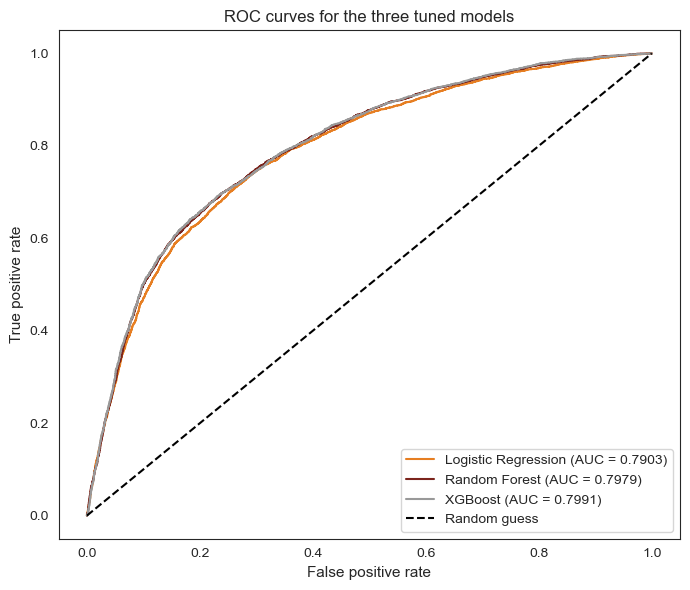

In [46]:
# Plot the ROC curve for the three tuned models on the same axes to compare them visually
# This uses the same style as the ROC curve for the default models so the two can be compared
plt.figure(figsize=(7, 6))

# For each tuned model, compute the false positive rate and true positive rate across thresholds, then plot the curve
tuned_log_reg_fpr, tuned_log_reg_tpr, _ = roc_curve(y_test, tuned_log_reg_proba)
plt.plot(tuned_log_reg_fpr, tuned_log_reg_tpr, label='Logistic Regression (AUC = {:.4f})'.format(roc_auc_score(y_test, tuned_log_reg_proba)), color='#e67e22')
tuned_rf_fpr, tuned_rf_tpr, _ = roc_curve(y_test, tuned_rf_proba)
plt.plot(tuned_rf_fpr, tuned_rf_tpr, label='Random Forest (AUC = {:.4f})'.format(roc_auc_score(y_test, tuned_rf_proba)), color='#7b241c')
tuned_xgb_fpr, tuned_xgb_tpr, _ = roc_curve(y_test, tuned_xgb_proba)
plt.plot(tuned_xgb_fpr, tuned_xgb_tpr, label='XGBoost (AUC = {:.4f})'.format(roc_auc_score(y_test, tuned_xgb_proba)), color='#999999')

# Add the diagonal line that represents a model with no predictive ability (random guessing)
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random guess')
plt.title('ROC curves for the three tuned models')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

The comparison shows that the effect of the tuning was different for each model. For Logistic Regression almost nothing changed, which is expected: the default model was already not overfitting, so the best regularisation strength found by cross-validation was C=1.00 and the training and test scores stayed essentially the same. For XGBoost the change was small as well, since the default model was already not overfitting either. The tuned XGBoost keeps a similar test accuracy and slightly improves its AUC-ROC from 0.7926 to 0.7991, with the lower learning rate and shallower trees making the model a little more stable without changing its overall performance.

The tuning mattered most for Random Forest, where it clearly reduced the overfitting. With the best depth found by cross-validation (max_depth=14) and min_samples_leaf fixed at 5, the training accuracy dropped from a near-perfect 0.9998 to 0.7735, so the forest no longer fits every training patient exactly. Limiting the depth and leaf size therefore made the forest simpler and less overfitted, while actually improving how well it generalises: its test accuracy rose from 0.7123 to 0.7294 and its AUC-ROC from 0.7717 to 0.7979. The confusion matrices make this concrete in terms of the errors that matter clinically. Out of the 6793 patients who actually have the disease in the test set, the tuned Random Forest misses 2174 (false negatives), compared with 2186 for the tuned XGBoost and 2322 for Logistic Regression, so the two tree-based models make slightly fewer dangerous misses than the linear baseline. In a clinical setting a false negative, missing a patient who actually has the disease, is usually more serious than a false alarm, so reducing the false negatives is the more valuable change.

Taken together, the tuning reduced the overfitting in Random Forest, while Logistic Regression and XGBoost were already stable. The three tuned models perform very similarly. The tuned Random Forest leads on most of the test metrics, with the highest test accuracy (0.7294), F1 score (0.7132) and recall (0.6800), while the tuned XGBoost has the highest AUC-ROC (0.7991), which means it separates the two classes slightly better across all thresholds. The two are extremely close on every metric, with differences of only a few thousandths. Because the models are so similar and XGBoost was the main model of interest in the analysis of the other dataset, XGBoost is kept as the main model here as well for consistency, while the tuned Random Forest stands as an equally strong alternative. For this reason the explainability and fairness analysis in the following sections focuses on the tuned models, with XGBoost as the main model of interest, while still keeping all three for comparison.

## 7. Explainability (SHAP and LIME)

The models predict cardiovascular disease with reasonable accuracy but do not show *why* a prediction was made. This section uses two explainability tools, SHAP and LIME, to see which features drive the predictions and whether the models rely on them differently for female and male patients.

SHAP (SHapley Additive exPlanations) gives each feature a value showing how much it pushed a prediction up or down. It is used in three roles, kept separate throughout:
- **Global SHAP** ranks which features matter most across all patients.
- **Local SHAP** explains a single patient's prediction, the kind of case-level explanation a clinician would need.
- **Gender-stratified SHAP** compares feature importance for female and male patients separately, which is the bridge to the fairness analysis.

LIME (Local Interpretable Model-agnostic Explanations) is then used as a second check on the local explanations. The analysis focuses on the tuned XGBoost, with the tuned Random Forest examined afterwards as a comparison. Both are tree-based, so TreeExplainer is used to compute their SHAP values.

### SHAP setup

A TreeExplainer is built for the tuned XGBoost model and the SHAP values are computed on the test set, so the explanations describe how the model behaves on patients it did not see during training. Because the features were scaled during preprocessing, the scaled test set is wrapped back into a data frame with the original column names so that the plots show readable feature names.

In [47]:
# Import the SHAP library for explaining the model predictions
import shap

# Wrap the scaled test set back into a data frame so the feature names are available for the SHAP plots
X_test_df = pd.DataFrame(X_test, columns=X.columns)

# Build a TreeExplainer for the tuned XGBoost model
# TreeExplainer is the fast and exact SHAP algorithm for tree-based models
explainer_xgb = shap.TreeExplainer(tuned_xgb)

# Compute the SHAP values for every patient in the test set
shap_values_xgb = explainer_xgb.shap_values(X_test_df)

# Confirm the shape of the SHAP values: one value per patient per feature
print('SHAP values computed for the tuned XGBoost model')
print('Shape of the SHAP values: {}'.format(shap_values_xgb.shape))
print('This is {} patients and {} features'.format(shap_values_xgb.shape[0], shap_values_xgb.shape[1]))

SHAP values computed for the tuned XGBoost model
Shape of the SHAP values: (13731, 11)
This is 13731 patients and 11 features


### Global SHAP

Global SHAP summarises how the model uses each feature across all patients in the test set. Two plots are produced. The first is a summary (beeswarm) plot, where each row is a feature ranked by importance and each dot is one patient: the horizontal position shows how much that feature pushed that patient's prediction towards or away from cardiovascular disease, and the colour shows whether the feature value was high or low. The second is a bar plot showing the mean absolute SHAP value for each feature, which is a simpler ranking of overall importance. Together they show not just which features matter most, but in which direction they push the prediction.

In [48]:
# Map the short column names to readable labels for the SHAP plots, matching the labels used earlier
readable_labels = {'age': 'Age', 'gender': 'Gender', 'height': 'Height', 'weight': 'Weight', 'ap_hi': 'Systolic BP', 'ap_lo': 'Diastolic BP', 'cholesterol': 'Cholesterol', 'gluc': 'Glucose', 'smoke': 'Smoking', 'alco': 'Alcohol', 'active': 'Active'}

# Build a version of the test set with readable feature names so the SHAP plots are clear
X_test_display = X_test_df.rename(columns=readable_labels)

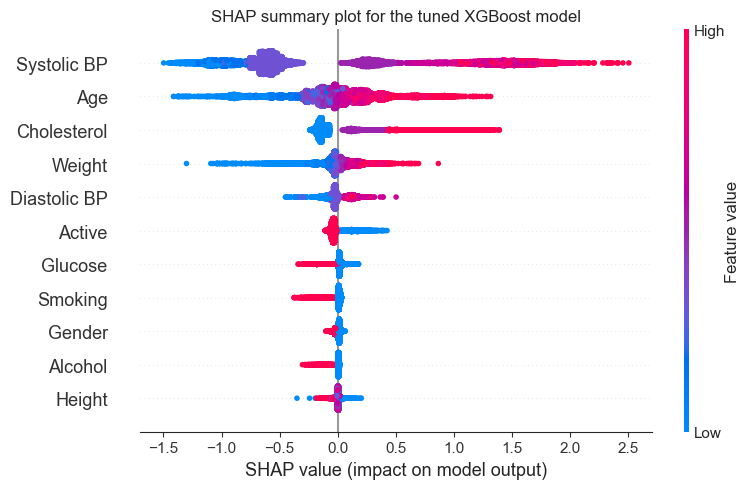

In [49]:
# Plot the global SHAP summary (beeswarm) for the tuned XGBoost model
# Each row is a feature, each dot is a patient, and the colour shows whether the feature value was high or low
shap.summary_plot(shap_values_xgb, X_test_display, plot_size=(8, 5), show=False)
plt.title('SHAP summary plot for the tuned XGBoost model')
plt.tight_layout()
plt.show()

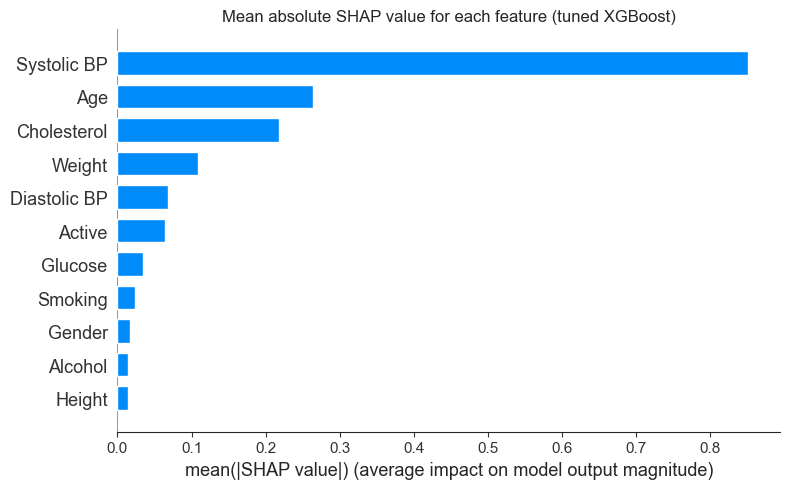

In [50]:
# Plot the mean absolute SHAP value for each feature as a bar chart
# This is a simpler ranking of overall feature importance
shap.summary_plot(shap_values_xgb, X_test_display, plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (tuned XGBoost)')
plt.tight_layout()
plt.show()

The two plots agree on which features the model relies on most. Systolic blood pressure is by far the strongest driver, followed by age, cholesterol and weight, while diastolic blood pressure, physical activity, glucose and smoking sit in the middle. Gender, alcohol intake and height contribute the least, with gender ranking ninth out of eleven features. This ordering is close to the univariate feature ranking seen earlier, where systolic blood pressure also stood out as the strongest single predictor, which is reassuring: the model relies on the same clinically meaningful measurements that the simple statistical tests highlighted. The very low importance of gender is notable, and it is examined directly in the gender-stratified analysis below.

The summary plot adds the direction of each effect. For the numerical features the colour reads directly, since red marks high values and blue marks low values: high systolic and diastolic blood pressure, high age, high cholesterol and high weight all tend to push the prediction towards cardiovascular disease, while low values push it away. These directions are clinically sensible, as raised blood pressure, older age and higher cholesterol are all recognised risk factors. The categorical features were converted to numbers during preprocessing, so their colours follow the encoding rather than a natural scale. Gender is encoded as Male=1 and Female=0, but its SHAP values are clustered tightly around zero for both groups, which shows that the model barely uses gender to separate patients in either direction. This is an early sign that gender carries little predictive signal in this dataset, in contrast to the stronger role it can play when base rates differ between the sexes.

One caveat applies to all of these readings. SHAP shows how the model uses each feature, not what causes cardiovascular disease, so a high SHAP value for a feature means the model relied on it, not that the feature is a clinical cause. The values are also computed under an assumption of feature independence, so for the clinical features that are mildly correlated, such as systolic and diastolic blood pressure, the attributions should be read as a guide to the model's behaviour rather than as exact quantities.

### Local SHAP

Global SHAP showed which features matter across all patients, but a clinician treating one person needs to know why the model reached its decision for that specific patient. Local SHAP answers this by explaining a single prediction: it shows, for one patient, how each feature pushed the predicted risk up or down, starting from the base value (the average prediction across the data) and ending at the final prediction for that patient. This is the case-level explanation a doctor would need to decide whether to trust and act on the model's output.

The explanation is shown with a waterfall plot, which lists the features for one patient from the most influential at the top to the least at the bottom. Each bar shows how much that feature moved the prediction: red bars push the prediction towards cardiovascular disease and blue bars push it away. Two patients are shown for contrast, one the model predicts has disease and one it predicts is healthy, so the difference in how the features behave can be seen directly.

In [51]:
# Build a separate explainer for the local explanations, which return the SHAP values together with the feature values for each patient
# A sample of 1000 training patients is used as the background, with readable feature names for the plots
X_train_display = X_train_df.rename(columns=readable_labels)
masker = shap.maskers.Independent(X_train_display, max_samples=1000)
local_explainer_xgb = shap.Explainer(tuned_xgb, masker)

# Compute the local explanations for the test set patients, using the same readable names
local_shap_xgb = local_explainer_xgb(X_test_display)

# Confirm the explanation has one entry per patient with the base value and the per-feature contributions
print('Local explanations computed for the tuned XGBoost model')
print('Number of patients explained: {}'.format(local_shap_xgb.shape[0]))
print('Number of features per patient: {}'.format(local_shap_xgb.shape[1]))

Background dataset has 54922 samples but max_samples=1000. Subsampling to 1000 samples for SHAP value computation. To use all samples, set max_samples=54922 when initializing the masker.
100%|===================| 13714/13731 [02:11<00:00]        

Local explanations computed for the tuned XGBoost model
Number of patients explained: 13731
Number of features per patient: 11


Patient 4540: actual = 0, predicted probability of disease = 0.945


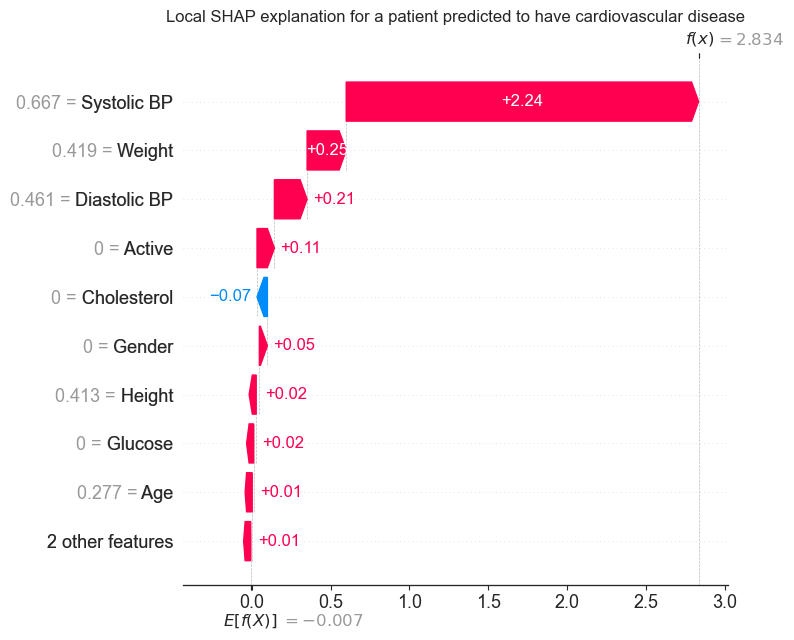

In [52]:
# Pick the patient with the highest predicted probability of disease
probabilities = tuned_xgb.predict_proba(X_test_df)[:, 1]
patient_with_disease = probabilities.argmax()
patient_without_disease = probabilities.argmin()

# Explain the patient the model predicts has cardiovascular disease
print('Patient {}: actual = {}, predicted probability of disease = {:.3f}'
    .format(patient_with_disease, y_test.values[patient_with_disease], 
            probabilities[patient_with_disease]))

shap.plots.waterfall(local_shap_xgb[patient_with_disease], show=False)
plt.title('Local SHAP explanation for a patient predicted to have cardiovascular disease')
plt.tight_layout()
plt.show()

Patient 11780: actual = 0, predicted probability of disease = 0.015


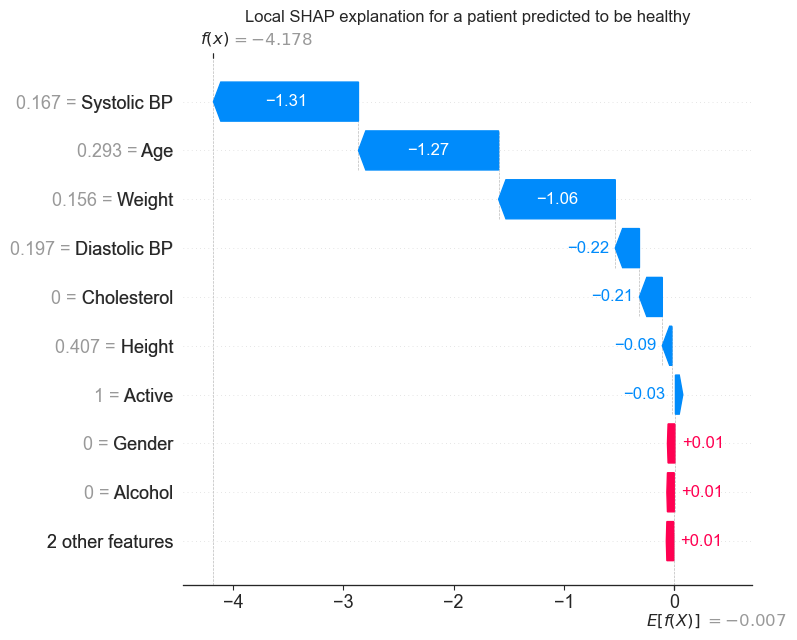

In [53]:
# Explain the patient the model predicts is healthy, for contrast
print('Patient {}: actual = {}, predicted probability of disease = {:.3f}'
    .format(patient_without_disease, y_test.values[patient_without_disease], 
            probabilities[patient_without_disease]))

shap.plots.waterfall(local_shap_xgb[patient_without_disease], show=False)
plt.title('Local SHAP explanation for a patient predicted to be healthy')
plt.tight_layout()
plt.show()

The two waterfall plots are read from the base value at the bottom, which is the average prediction across the background patients (-0.007 in log-odds), up to the model's output for that patient. The two cases chosen are the ones the model was most confident about, so the contrast between them is clear.

For the patient predicted to have cardiovascular disease, almost every feature pushes the prediction towards disease, taking the output from the base value up to 2.834. Systolic blood pressure is by far the strongest push (+2.24), followed by weight (+0.25) and diastolic blood pressure (+0.21), with only cholesterol pulling slightly the other way (-0.07). For the patient predicted to be healthy, the features push the other way, taking the output down to -4.178, with systolic blood pressure (-1.31), age (-1.27) and weight (-1.06) being the strongest. The same features therefore act in opposite directions for these two patients, which is exactly what a local explanation is meant to show: how the model reached its decision for one individual rather than on average.

Gender plays almost no role in either case, contributing only +0.05 for the first patient and +0.01 for the second. This is consistent with the global analysis, where gender ranked near the bottom of the features: the model decides on the basis of blood pressure, age and weight rather than gender, even at the level of individual patients. As before, these readings describe how the model used each feature for these patients, not a clinical cause of cardiovascular disease.

### Gender-stratified SHAP

The global and local analyses showed that gender is one of the features the model relies on least. This section looks at that more directly by computing SHAP separately for female and male patients, to see whether the model uses the features differently for the two groups. A difference in how a feature is used across the sexes is a possible source of the bias examined in the fairness analysis later.

The same SHAP values from the global analysis are split into the female and male patients, and a mean absolute SHAP bar plot is produced for each group. Comparing the two rankings shows whether any feature, in particular gender itself, carries a different weight for female and male patients. The male group is smaller (4741 patients against 8990), so its ranking is based on fewer cases, although both groups are large enough for the comparison to be stable.

In [54]:
# Split the test set patients into female and male using the encoded gender column
female_mask = X_test_df['gender'] == 0
male_mask = X_test_df['gender'] == 1

# Take the SHAP values for each group separately, using the same values computed for the global analysis
female_shap_xgb = shap_values_xgb[female_mask.values]
male_shap_xgb = shap_values_xgb[male_mask.values]

# Confirm how many patients fall into each group
print('Female patients in the test set: {}'.format(female_mask.sum()))
print('Male patients in the test set: {}'.format(male_mask.sum()))
print('Shape of female SHAP values: {}'.format(female_shap_xgb.shape))
print('Shape of male SHAP values: {}'.format(male_shap_xgb.shape))

Female patients in the test set: 8990
Male patients in the test set: 4741
Shape of female SHAP values: (8990, 11)
Shape of male SHAP values: (4741, 11)


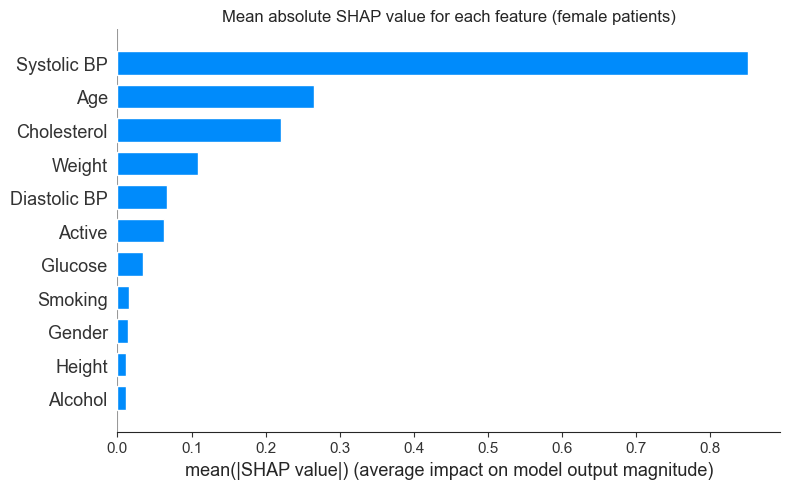

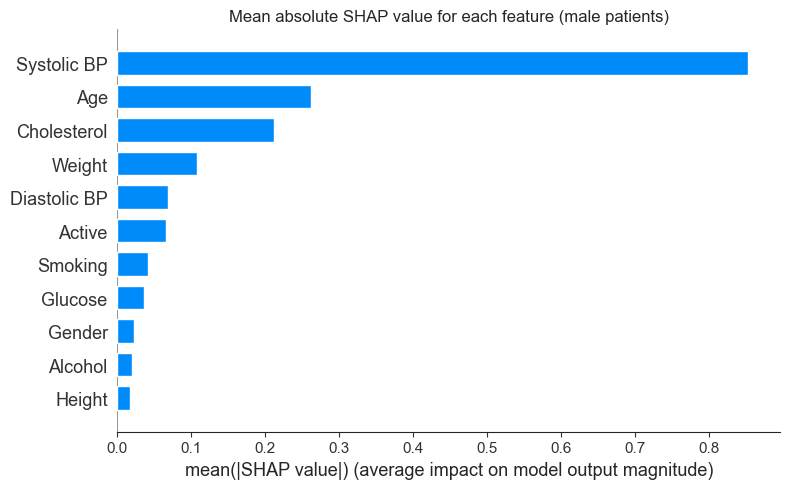

In [55]:
# Plot the mean absolute SHAP value for each feature for the female patients only
shap.summary_plot(female_shap_xgb, X_test_display[female_mask.values], plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (female patients)')
plt.tight_layout()
plt.show()

# Plot the same for the male patients only, so the two rankings can be compared
shap.summary_plot(male_shap_xgb, X_test_display[male_mask.values], plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (male patients)')
plt.tight_layout()
plt.show()

In [56]:
# Take the SHAP values for the gender feature only, for each group, keeping the sign to show direction
female_gender_shap_xgb = pd.DataFrame(female_shap_xgb, columns=X.columns)['gender']
male_gender_shap_xgb = pd.DataFrame(male_shap_xgb, columns=X.columns)['gender']

# A negative value pushes towards no disease, a positive value towards disease
print('Mean SHAP for gender, female patients: {:.4f}'.format(female_gender_shap_xgb.mean()))
print('Mean SHAP for gender, male patients: {:.4f}'.format(male_gender_shap_xgb.mean()))

Mean SHAP for gender, female patients: 0.0136
Mean SHAP for gender, male patients: -0.0224


The two bar plots show that the model relies on the features in almost the same way for the two genders. For both female and male patients systolic blood pressure is the single most important feature, followed by age, cholesterol and weight, and gender ranks near the bottom in both groups, ninth out of eleven features. The orderings are close to identical, with only minor swaps among the least important features, which is a first sign that the model does not treat the two genders differently in this dataset.

The direction of the gender effect confirms this. Averaged across each group, the mean SHAP value for gender is only +0.0136 for female patients and -0.0224 for male patients. Both values are very close to zero, so gender barely moves the prediction in either group, and the small difference between them is negligible compared with the strong clinical features. Gender is not acting as a meaningful signal for either group.

This is the clearest sign that the model treats the two genders in essentially the same way. It relies on the same clinical measurements, mainly blood pressure, age and cholesterol, to assess both female and male patients, and gender itself plays almost no part in either case. This is the opposite of the pattern that can appear when the base rates differ sharply between the genders, where a model may lean on gender itself and assess the two groups differently. Here the near-equal base rates leave little room for that kind of divergence.

As with the earlier SHAP results, this describes how the model uses gender, not a clinical cause of cardiovascular disease. Both groups are large (8990 female and 4741 male patients), so the rankings are stable and the comparison can be read with confidence rather than as the result of a small sample.

### LIME

SHAP explained the predictions using a single, theoretically grounded method. LIME (Local Interpretable Model-agnostic Explanations) is used here as a second, independent check on those local explanations. It works in a completely different way: instead of using game theory, it slightly changes the patient's feature values many times, watches how the prediction reacts, and fits a simple linear model around that one patient to see which features mattered most. If LIME points to the same features as SHAP for the same patient, that agreement gives more confidence that the explanation reflects the model rather than the quirks of one method.

The same two patients explained with SHAP are used again, the one the model is most confident has cardiovascular disease and the one it is most confident is healthy, so the two tools can be compared directly on the same cases.

In [57]:
# Import the LIME library for explaining individual predictions
import lime
import lime.lime_tabular

# The categorical columns are given to LIME by their index so it does not treat them as continuous
# gender, cholesterol, glucose, smoke, alcohol and active are at positions 1, 6, 7, 8, 9 and 10
categorical_features = [1, 6, 7, 8, 9, 10]

# Build the LIME explainer on the training data, with the readable feature names used for the SHAP plots and class labels
# The random state is fixed so the explanations are reproducible
lime_explainer = lime.lime_tabular.LimeTabularExplainer(X_train, mode='classification',
                                                        feature_names=X_test_display.columns.tolist(),
                                                        categorical_features=categorical_features,
                                                        class_names=['No disease', 'Disease'],
                                                        random_state=random_state)

LIME explanation for the patient predicted to have cardiovascular disease (patient 4540)


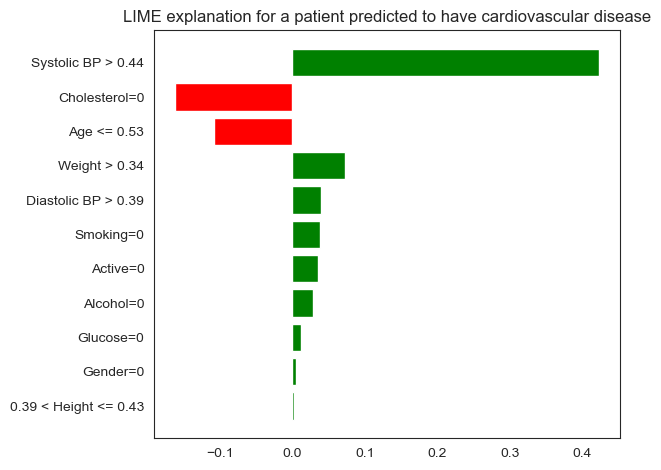

In [58]:
# Explain the same two patients used for the local SHAP analysis, found earlier with argmax and argmin
# Explain the patient predicted to have cardiovascular disease, asking LIME for all eleven features
exp_disease = lime_explainer.explain_instance(X_test[patient_with_disease], tuned_xgb.predict_proba, num_features=11)
print('LIME explanation for the patient predicted to have cardiovascular disease (patient {})'.format(patient_with_disease))

# Show the explanation as a bar chart, where each bar is a feature pushing the prediction towards disease or no disease
exp_disease.as_pyplot_figure()
plt.title('LIME explanation for a patient predicted to have cardiovascular disease')
plt.tight_layout()
plt.show()

LIME explanation for the patient predicted to be healthy (patient 11780)


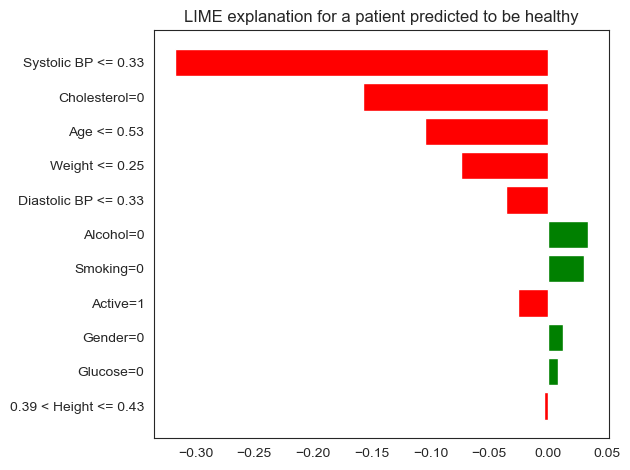

In [59]:
# Explain the patient predicted to be healthy, for contrast, again asking LIME for all eleven features
exp_healthy = lime_explainer.explain_instance(X_test[patient_without_disease], tuned_xgb.predict_proba, num_features=11)
print('LIME explanation for the patient predicted to be healthy (patient {})'.format(patient_without_disease))

# Show the explanation as a bar chart, where each bar is a feature pushing the prediction towards disease or no disease
exp_healthy.as_pyplot_figure()
plt.title('LIME explanation for a patient predicted to be healthy')
plt.tight_layout()
plt.show()

The LIME results broadly agree with SHAP on which features matter, while differing slightly in their exact order. For the patient predicted to have cardiovascular disease, LIME highlights systolic blood pressure as the main feature pushing the prediction towards disease, which is the same feature SHAP found most important, with weight, diastolic blood pressure and age also appearing. For the patient predicted to be healthy, the agreement is just as close: both methods put systolic blood pressure among the strongest features, with cholesterol, age and weight also leading the ranking towards no disease. Gender appears near the bottom for both patients under both methods, which reinforces the gender-stratified finding that the model relies on gender very little rather than depending on one tool.

Some difference between the two methods is expected and does not undermine the explanations. SHAP and LIME belong to the same family of additive feature-attribution methods, but they compute their values differently: SHAP uses the exact game-theoretic Shapley values, while LIME fits a simple linear model in the local neighbourhood of the patient and so produces an approximation that depends on its sampling and on how it treats each feature. This is why the two can rank features in a slightly different order. For this reason SHAP is treated as the main explainability method in this project and LIME as a supporting check: where the two agree, as they do here on the leading features and on the small role of gender, the explanation is more trustworthy because it does not rely on the assumptions of a single method.

### Comparing with Random Forest

All of the explanations so far have used the tuned XGBoost, the main model of this study. A natural question is whether the patterns found, in particular the way gender is used for female and male patients, come from the data itself or are specific to XGBoost. To check this, the same SHAP analysis is repeated for the tuned Random Forest, the second tree-based model. If a different model trained on the same data shows the same pattern, that points to the pattern being a property of the data rather than of one algorithm.

Random Forest is also tree-based, so its SHAP values are computed with TreeExplainer. The global ranking and the gender-stratified comparison are produced for the Random Forest and placed next to the XGBoost results, which is enough to see whether the two models rely on gender in the same way.

In [60]:
# Build a TreeExplainer for the tuned Random Forest, which is also tree-based
explainer_rf = shap.TreeExplainer(tuned_rf)

# Compute the SHAP values, keeping the disease class (index 1) since a scikit-learn classifier returns both classes
shap_values_rf = explainer_rf.shap_values(X_test_df)[:, :, 1]

# Confirm the shape: one value per patient per feature, for the disease class
print('SHAP values computed for the tuned Random Forest model')
print('Shape of the SHAP values: {}'.format(shap_values_rf.shape))
print('This is {} patients and {} features'.format(shap_values_rf.shape[0], shap_values_rf.shape[1]))

SHAP values computed for the tuned Random Forest model
Shape of the SHAP values: (13731, 11)
This is 13731 patients and 11 features


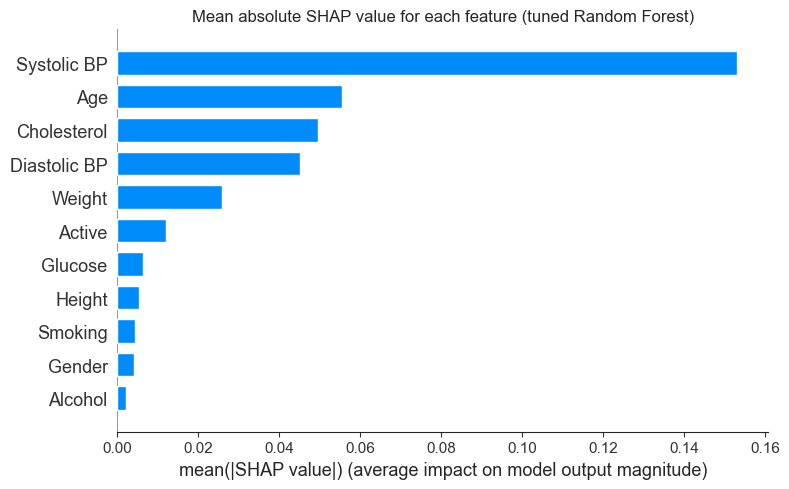

In [61]:
# Plot the mean absolute SHAP value for each feature for the Random Forest, to compare its ranking with XGBoost
shap.summary_plot(shap_values_rf, X_test_display, plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (tuned Random Forest)')
plt.tight_layout()
plt.show()

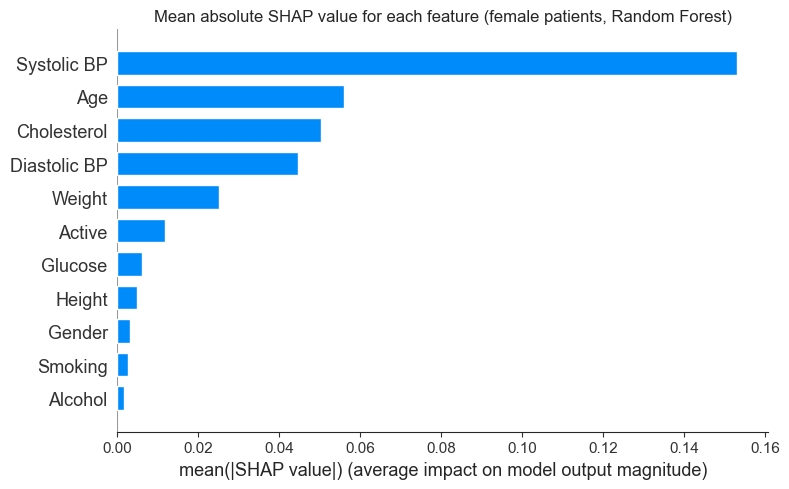

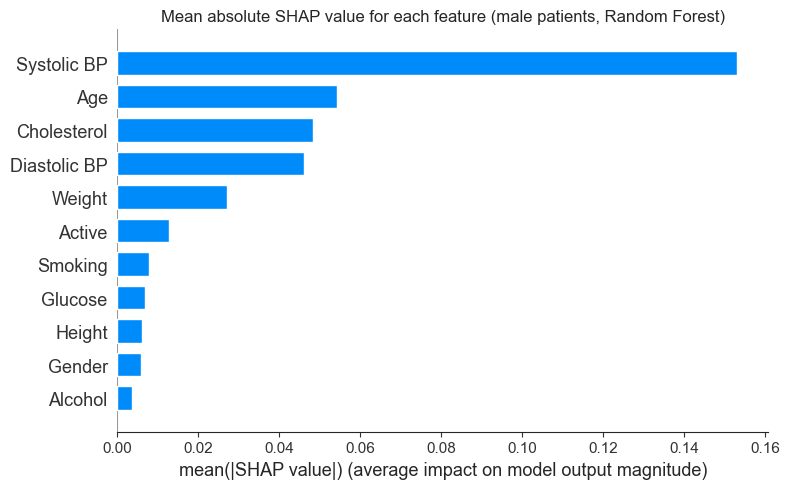

In [62]:
# Split the Random Forest SHAP values into female and male, using the same masks as before
female_shap_rf = shap_values_rf[female_mask.values]
male_shap_rf = shap_values_rf[male_mask.values]

# Plot the mean absolute SHAP value for each feature for the female patients only
shap.summary_plot(female_shap_rf, X_test_display[female_mask.values], plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (female patients, Random Forest)')
plt.tight_layout()
plt.show()

# Plot the same for the male patients only, so the two rankings can be compared
shap.summary_plot(male_shap_rf, X_test_display[male_mask.values], plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (male patients, Random Forest)')
plt.tight_layout()
plt.show()

In [63]:
# Take the Random Forest SHAP values for the gender feature only, for each group, keeping the sign to show direction
female_gender_shap_rf = pd.DataFrame(female_shap_rf, columns=X.columns)['gender']
male_gender_shap_rf = pd.DataFrame(male_shap_rf, columns=X.columns)['gender']

# A negative value pushes towards no disease, a positive value towards disease
print('Mean SHAP for gender, female patients (Random Forest): {:.4f}'.format(female_gender_shap_rf.mean()))
print('Mean SHAP for gender, male patients (Random Forest): {:.4f}'.format(male_gender_shap_rf.mean()))

Mean SHAP for gender, female patients (Random Forest): 0.0026
Mean SHAP for gender, male patients (Random Forest): -0.0047


The Random Forest shows the same pattern as XGBoost. In its global ranking the leading features are the same, with systolic blood pressure, age and cholesterol at the top and gender near the bottom. More importantly, the gender-stratified comparison repeats the XGBoost finding: gender ranks low for both female and male patients, and its mean SHAP value is only +0.0026 for female patients and -0.0047 for male patients, both close to zero just as they were for XGBoost.

The size of the Random Forest values is smaller than the XGBoost ones, but this is expected and not meaningful on its own, because the two models report their output on different scales. What matters is that the shape of the result is the same: neither model leans on gender for either group, and both treat the two genders in the same way. Because two different models, one boosting and one bagging, trained on the same data produce the same pattern, this points to the result coming from the data rather than from a single algorithm. It strengthens the earlier finding that gender carries little weight in this dataset, which is what the fairness analysis examines next.

## 8. Fairness Analysis

The explainability analysis showed that the model uses gender very little for female and male patients. This section measures whether the model's behaviour translates into unfair outcomes, by comparing the two groups across five fairness metrics. The analysis focuses on the tuned XGBoost first, then summarises all three models.

A model can be accurate overall while still treating two groups differently. To capture this, the predictions are split by gender and the following are compared between female and male patients: the basic error rates (false negative and false positive rate), and five fairness metrics. The false negative rate matters most clinically, since a false negative means a patient who truly has cardiovascular disease is predicted healthy, so a higher false negative rate for one group means that group's real cases are missed more often.

The five fairness metrics each capture a different idea of fairness:

- **Demographic parity** asks whether the model predicts disease at the same rate for both genders.
- **Equalised odds** asks whether the true positive and false positive rates are the same for both genders.
- **Predictive parity** asks whether a positive prediction is equally trustworthy for both genders (equal precision).
- **Disparate impact** is the ratio of the two positive-prediction rates, where a ratio of 1 indicates equal positive-prediction rates and 0.8 is the four-fifths reference threshold.
- **Calibration** asks whether a predicted probability means the same thing for both genders.

These metrics cannot all be satisfied at once when the two groups have different base rates. In this dataset the base rates are very close (the disease rate is 49.96% for male patients and 49.21% for female patients), so the sharp trade-off that the impossibility result describes is expected to be very small here. This is the impossibility result that the project sets out to present rather than solve, and the analysis below shows how little trade-off appears when the base rates are nearly equal.

In [64]:
# Import the fairness metrics from Fairlearn and the calibration tools from scikit-learn
from fairlearn.metrics import MetricFrame, false_negative_rate, false_positive_rate, true_positive_rate, true_negative_rate, selection_rate
from fairlearn.metrics import demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference
from sklearn.calibration import calibration_curve

In [65]:
# Map the encoded gender column to readable labels so the fairness metrics are grouped clearly
gender_labels = X_test_df['gender'].map({0: 'Female', 1: 'Male'})

# Confirm the gender labels match the expected counts from the test set
print('Gender label counts in the test set:\n{}'.format(gender_labels.value_counts()))

Gender label counts in the test set:
gender
Female    8990
Male      4741
Name: count, dtype: int64


### Performance by gender

Before computing the formal fairness metrics, the basic performance of the tuned XGBoost is compared between female and male patients. The recall (true positive rate) shows how many real disease cases the model catches in each group, and the false negative rate shows the share of real cases it misses. A higher false negative rate for one group would mean that group's true cases are missed more often, which is the concern the gender-stratified explanation looked at earlier. Precision and the false positive rate are shown alongside to give the full picture.

In [66]:
# Compare the basic performance of the tuned XGBoost between female and male patients
# A dictionary of metrics is passed so MetricFrame returns one row per gender for each metric
performance_metrics = {'Recall': recall_score, 'Precision': precision_score, 'False negative rate': false_negative_rate, 'False positive rate': false_positive_rate}

# MetricFrame splits the predictions by gender and computes each metric separately for each group
performance_by_gender = MetricFrame(metrics=performance_metrics,
                                    y_true=y_test,
                                    y_pred=tuned_xgb_pred,
                                    sensitive_features=gender_labels)

# Show the metrics for each gender side by side
print('Performance by gender for the tuned XGBoost:\n{}'.format(performance_by_gender.by_group.round(4)))

Performance by gender for the tuned XGBoost:
        Recall  Precision  False negative rate  False positive rate
gender                                                             
Female  0.6774     0.7459               0.3226               0.2210
Male    0.6797     0.7569               0.3203               0.2229


The performance is almost identical for the two groups. The recall is 0.6774 for female patients and 0.6797 for male patients, so the model catches real disease cases at essentially the same rate in both groups. The false negative rate, which matters most clinically, is 0.3226 for female patients and 0.3203 for male patients, a difference of only about two thousandths. Neither group has its real cases missed more often than the other, which is the opposite of the under-diagnosis concern that can appear when a model leans on gender.

The other measures tell the same story. Precision is 0.7459 for female patients and 0.7569 for male patients, so a positive prediction is about as trustworthy for one group as for the other. The false positive rate is also very close, 0.2210 for female patients against 0.2229 for male patients, meaning healthy patients are flagged at almost the same rate in both groups. There is no sign here of the opposing error-rate pattern, where one group carries a much higher false negative rate and the other a much higher false positive rate.

These figures can be read with confidence because both groups are large, with 8990 female and 4741 male patients in the test set, so the rates are not the result of a small sample. The closeness of the two columns is consistent with the explainability results and follows from the near-equal base rates: when the disease rate is almost the same for both groups, there is little room for the model to perform differently for one of them. This is the setting in which the fairness metrics below are expected to show only small gaps.

### The five fairness metrics

The five fairness metrics are now computed for the tuned XGBoost. Four of them are reported as a single number summarising the gap between the two genders. Demographic parity, equalised odds and disparate impact use the Fairlearn functions directly. Predictive parity has no direct function, so it is computed as the difference in precision between the two groups, taken from the per-gender precision already seen above. For the difference metrics a value of 0 means the two genders are treated identically, while for disparate impact a ratio of 1 means identical treatment and 0.8 is the four-fifths reference threshold. Calibration is handled separately afterwards.

In [67]:
# Compute the four threshold-based fairness metrics for the tuned XGBoost
# Demographic parity, equalised odds and disparate impact have direct Fairlearn functions
dp_difference = demographic_parity_difference(y_test, tuned_xgb_pred, sensitive_features=gender_labels)
eo_difference = equalized_odds_difference(y_test, tuned_xgb_pred, sensitive_features=gender_labels)
di_ratio = demographic_parity_ratio(y_test, tuned_xgb_pred, sensitive_features=gender_labels)

# Predictive parity has no direct function, so it is the difference in precision between the two groups
precision_by_gender = MetricFrame(metrics=precision_score,
                                  y_true=y_test,
                                  y_pred=tuned_xgb_pred,
                                  sensitive_features=gender_labels)
pp_difference = precision_by_gender.difference()

# Print the four metrics together
print('Demographic parity difference: {:.4f}'.format(dp_difference))
print('Equalised odds difference: {:.4f}'.format(eo_difference))
print('Predictive parity difference: {:.4f}'.format(pp_difference))
print('Disparate impact ratio: {:.4f}'.format(di_ratio))

Demographic parity difference: 0.0094
Equalised odds difference: 0.0024
Predictive parity difference: 0.0110
Disparate impact ratio: 0.9792


All four metrics show only a tiny gap between the two genders. The demographic parity difference is 0.0094, meaning the model predicts disease at almost the same rate for women and men. The disparate impact ratio is 0.9792, which is well above the 0.8 four-fifths reference and very close to the 1.0 of identical treatment. The equalised odds difference is 0.0024 and the predictive parity difference is 0.0110, so the gaps in recall and precision already seen in the performance table are confirmed here as negligible. By every one of these measures the two groups are treated almost identically.

The important point is that all four metrics are satisfied at the same time. This is not a coincidence but the expected consequence of the two groups having almost equal base rates: when the disease rate is nearly the same for both groups, the conditions that force the fairness metrics into conflict do not apply, so they can all be close to fair together. This is the impossibility result seen from the other side. Rather than improving one metric at the cost of another, there is very little gap to close in the first place, and the mitigation section will show how little room there is to change a model that is already close to fair across these metrics.

### Calibration by gender

The final fairness metric is calibration, which asks whether a predicted probability means the same thing for both genders. A model is well calibrated if, among patients given a predicted risk of around 0.7, about 70% truly have cardiovascular disease, and this should hold equally for women and men. Calibration is shown here with a reliability diagram, where the predicted probability is plotted against the observed proportion of real cases in each bin, separately for each gender. A curve close to the diagonal means the predicted probabilities can be trusted, while a curve below the diagonal means the model overestimates risk and a curve above means it underestimates. Both groups are large, so the curves are based on many patients and can be read with confidence.

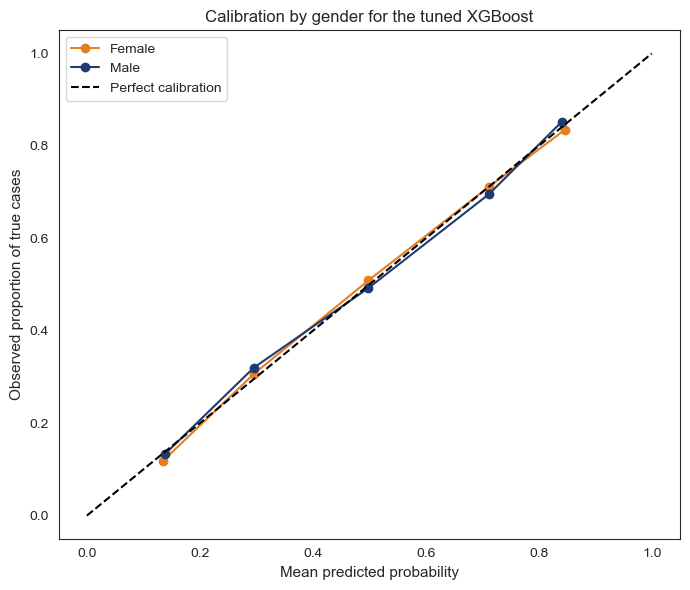

In [68]:
# Assess calibration separately for female and male patients using a reliability diagram
tuned_xgb_proba = tuned_xgb.predict_proba(X_test)[:, 1]

# Compute the calibration curve for each gender, using the same masks as the gender analysis
female_prob_true, female_prob_pred = calibration_curve(y_test[female_mask.values], tuned_xgb_proba[female_mask.values], n_bins=5)
male_prob_true, male_prob_pred = calibration_curve(y_test[male_mask.values], tuned_xgb_proba[male_mask.values], n_bins=5)

# Plot the two reliability curves together with the diagonal for perfect calibration
plt.figure(figsize=(7, 6))
plt.plot(female_prob_pred, female_prob_true, marker='o', color='#e67e22', label='Female')
plt.plot(male_prob_pred, male_prob_true, marker='o', color='#1f3b6f', label='Male')
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfect calibration')
plt.title('Calibration by gender for the tuned XGBoost')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed proportion of true cases')
plt.legend()
plt.tight_layout()
plt.show()

For most of the range the two curves sit almost exactly on the diagonal, which means the predicted probabilities can be trusted: when the model gives a patient a risk of around 0.4 or 0.6, close to that share of patients truly have disease, and this holds for both genders. The female and male curves follow each other closely across the whole range, staying near the diagonal from the lowest to the highest predicted risks, so the model is calibrated in much the same way for the two groups. There is only a very slight dip in the female curve at the highest predicted risks, where the model gives marginally higher scores than the observed rate, but the departure is small.

In line with the other four metrics, calibration shows no real split between the two genders: the curves are close to each other and close to the diagonal across the whole range, so a predicted probability means much the same thing for women and men. Both groups are large, so the curves can be read with confidence rather than as the result of a small sample. Taken together with the threshold-based metrics, calibration completes a consistent picture in which the model treats the two genders almost identically across every fairness measure used.

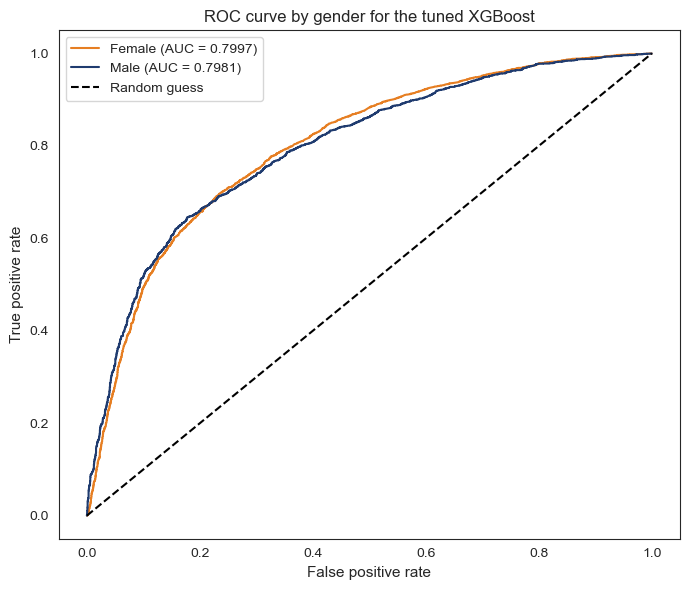

In [69]:
# Plot the ROC curve separately for female and male patients to visualise the equalised odds gap
female_fpr, female_tpr, _ = roc_curve(y_test[female_mask.values], tuned_xgb_proba[female_mask.values])
male_fpr, male_tpr, _ = roc_curve(y_test[male_mask.values], tuned_xgb_proba[male_mask.values])

# Plot both curves together with the diagonal line for a model with no predictive ability
plt.figure(figsize=(7, 6))
plt.plot(female_fpr, female_tpr, label='Female (AUC = {:.4f})'.format(roc_auc_score(y_test[female_mask.values], tuned_xgb_proba[female_mask.values])), color='#e67e22')
plt.plot(male_fpr, male_tpr, label='Male (AUC = {:.4f})'.format(roc_auc_score(y_test[male_mask.values], tuned_xgb_proba[male_mask.values])), color='#1f3b6f')
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random guess')
plt.title('ROC curve by gender for the tuned XGBoost')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.tight_layout()
plt.show()

The two curves lie almost on top of each other, with an area under the curve of 0.7997 for female patients and 0.7981 for male patients, a difference of less than two thousandths. This means the model separates disease cases from healthy ones about equally well in both groups across every possible threshold. There is no visible gap of the kind that would appear if the model ranked one group more reliably than the other.

This is the visual form of the equalised odds result seen earlier. When the two ROC curves sit almost on top of each other, the true positive and false positive rates are close across thresholds, which is consistent with the small equalised odds difference of 0.0024 at the shared threshold. Because both groups are large, the curves can be read with confidence rather than as the product of a small sample. The picture is the opposite of what would be expected if the model leaned on gender: there is no separation to close, so there is little for the mitigation stage to correct.

### What the fairness analysis shows for the tuned XGBoost

Taken together, the results show no real gap between the two genders on the threshold-based measures. The model selects the disease class at almost the same rate for women and men, misses a similar share of true cases in both groups, and the disparate impact ratio sits well above the 0.8 four-fifths reference, while demographic parity, equalised odds and predictive parity all show only tiny differences. Calibration is in line with this: the predicted probabilities behave in a broadly similar way for both groups, so a predicted risk means much the same thing for women and men, and the single decision threshold treats them almost identically.

This pattern is what the impossibility results lead one to expect. The disease base rate is almost the same for men and women in this dataset, and when the base rates are close a model can satisfy the fairness measures together rather than having to trade one against another. The ROC curves add that the model has similar discrimination across the two groups, which is consistent with the small equalised odds gap at the shared threshold. The aim of this section is to surface any trade-offs rather than to resolve them, and here the trade-offs are minimal. Because both groups are large, with 8990 female and 4741 male patients, these results can be read with confidence rather than as the product of a small sample.

### Fairness across the three models

The fairness analysis so far has focused on the tuned XGBoost as the main model. To check whether the closeness between the two genders is a property of one model or of the data itself, the four threshold-based metrics are now computed for all three tuned models side by side. Calibration is left out of this table because it is read from a curve rather than reduced to a single number, and it was already examined for the main model. If the same result appears for every model, that points to the data rather than to a single algorithm.

In [70]:
# Compute the four threshold-based fairness metrics for each tuned model on the test set
# Predictive parity is taken as the difference in precision between the genders, using a metric frame for each model
log_reg_precision_by_gender = MetricFrame(metrics=precision_score,
                                          y_true=y_test,
                                          y_pred=tuned_log_reg_pred,
                                          sensitive_features=gender_labels)
rf_precision_by_gender = MetricFrame(metrics=precision_score,
                                     y_true=y_test,
                                     y_pred=tuned_rf_pred,
                                     sensitive_features=gender_labels)
xgb_precision_by_gender = MetricFrame(metrics=precision_score,
                                      y_true=y_test,
                                      y_pred=tuned_xgb_pred,
                                      sensitive_features=gender_labels)

# Build a comparison table with the four fairness metrics for all three tuned models
fairness_comparison = pd.DataFrame({
    'Logistic Regression': [demographic_parity_difference(y_test, tuned_log_reg_pred, sensitive_features=gender_labels),
                            equalized_odds_difference(y_test, tuned_log_reg_pred, sensitive_features=gender_labels),
                            log_reg_precision_by_gender.difference(),
                            demographic_parity_ratio(y_test, tuned_log_reg_pred, sensitive_features=gender_labels)],
    'Random Forest': [demographic_parity_difference(y_test, tuned_rf_pred, sensitive_features=gender_labels),
                     equalized_odds_difference(y_test, tuned_rf_pred, sensitive_features=gender_labels),
                     rf_precision_by_gender.difference(),
                     demographic_parity_ratio(y_test, tuned_rf_pred, sensitive_features=gender_labels)],
    'XGBoost': [demographic_parity_difference(y_test, tuned_xgb_pred, sensitive_features=gender_labels),
               equalized_odds_difference(y_test, tuned_xgb_pred, sensitive_features=gender_labels),
               xgb_precision_by_gender.difference(),
               demographic_parity_ratio(y_test, tuned_xgb_pred, sensitive_features=gender_labels)]
}, index=['Demographic parity difference', 'Equalised odds difference', 'Predictive parity difference', 'Disparate impact ratio'])

# Show the fairness comparison rounded to four decimals for readability
print('Fairness comparison across the three tuned models:\n{}'.format(fairness_comparison.round(4)))

Fairness comparison across the three tuned models:
                               Logistic Regression  Random Forest  XGBoost
Demographic parity difference               0.0114         0.0097   0.0094
Equalised odds difference                   0.0069         0.0035   0.0024
Predictive parity difference                0.0124         0.0118   0.0110
Disparate impact ratio                      0.9743         0.9787   0.9792


The table shows the same pattern across all three models rather than in one of them alone. The disparate impact ratio sits well above the 0.8 four-fifths reference for every model (0.9743 for Logistic Regression, 0.9787 for Random Forest and 0.9792 for XGBoost), and demographic parity, equalised odds and predictive parity show only a tiny gap for each as well. Because the result recurs whether the model is a linear baseline, a bagged ensemble or a boosting method, it is better explained by the data than by any single algorithm. This agrees with the gender-stratified SHAP results, where two different models barely used gender at all, and it points back to the near-equal base rates between the two groups as the likely reason.

None of the three models shows the trade-off between the metrics that the impossibility result describes. Each one is close to fair on all four measures at the same time, with no model having to give up one metric to do well on another. This is the expected consequence of the near-equal base rates: the condition that forces the fairness metrics into conflict is not present here, so a model can satisfy them together rather than being pulled in different directions. Logistic Regression, Random Forest and XGBoost differ only slightly in their exact values, and all three stay well within the fair range on every metric.

The main point of this comparison is that choosing a different model does not change the outcome, which points back to the data rather than the algorithm. This sets up the mitigation section, where instead of swapping the model, the predictions are adjusted to see what effect this has on the metrics. Because the metrics are already close to fair, little change is expected, and as throughout the aim is to present these trade-offs rather than to claim any one model resolves them.

## 9. Bias Mitigation

The fairness analysis showed that the model treats the two genders almost identically, and that this pattern is present in every model because it comes from the data rather than the algorithm. This section asks a different question: when the predictions are already close to fair, does applying the standard mitigation methods change anything, and what do they cost on the other fairness metrics?

Three mitigation methods are applied, each at a different stage of the pipeline. The first two are pre-processing methods that change the training data before the model is fitted: oversampling the minority class, and reweighting the patients so that gender and the outcome are less strongly linked. The third is a post-processing method that leaves the trained model untouched and instead adjusts the decision threshold separately for each gender. In-processing methods, which change the learning algorithm itself, are outside the scope of this project.

All three methods are demonstrated on the tuned XGBoost, the main model of this study. Each method is applied only to the training data, after the train and test split, so that the test set stays untouched and the results are not affected by leakage. After each method the same fairness metrics are measured again, so that the effect of the mitigation can be compared against the baseline. Because the base rates are already close and the baseline metrics are already near fair, little change is expected here, in contrast to a setting where the base rates differ and the impossibility result forces a sharper trade-off.

### Oversampling with SMOTE

The first method addresses the class imbalance in the training data. SMOTE creates new synthetic patients for the minority class rather than simply copying existing ones: for each minority patient it finds its nearest neighbours of the same class and builds a new patient from them, so the added patients are plausible variations rather than exact duplicates.

Because the data has both continuous features, such as age and weight, and categorical ones, such as gender and cholesterol level, the SMOTE-NC variant is used, which is suited to this mix so that the categorical columns keep whole category values rather than meaningless in-between codes.

SMOTE is applied only to the training set, after the split, so that the test set still reflects the real population and the evaluation stays honest. A new XGBoost is then trained on the resampled data using the same tuned settings as before, and the fairness metrics are measured again on the untouched test set. SMOTE targets the balance between the disease classes rather than the balance between the genders directly, so its effect on the gender-based fairness metrics is examined rather than assumed.

In [71]:
# Import SMOTE-NC, the SMOTE variant for data with both continuous and categorical features
from imblearn.over_sampling import SMOTENC

# The six categorical columns are at these positions: gender, cholesterol, gluc, smoke, alco and active
# SMOTE-NC keeps these as whole categories instead of creating meaningless in-between values
categorical_indices = [1, 6, 7, 8, 9, 10]

# Resample only the training data so that the test set stays untouched and there is no leakage
smote = SMOTENC(categorical_features=categorical_indices, random_state=random_state, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Confirm the class balance before and after resampling
print('Training class balance before SMOTE-NC:\n{}'.format(pd.Series(y_train).value_counts()))
print('\nTraining class balance after SMOTE-NC:\n{}'.format(pd.Series(y_train_smote).value_counts()))

Training class balance before SMOTE-NC:
target
0    27750
1    27172
Name: count, dtype: int64

Training class balance after SMOTE-NC:
target
1    27750
0    27750
Name: count, dtype: int64


In [72]:
# Train a new XGBoost on the resampled data, keeping the same tuned settings as before
xgb_smote = XGBClassifier(max_depth=best_xgb_depth, learning_rate=0.05, n_estimators=150, random_state=random_state, eval_metric='logloss')
xgb_smote.fit(X_train_smote, y_train_smote)

# Predict on the untouched test set so the evaluation reflects the real population
xgb_smote_pred = xgb_smote.predict(X_test)

# Measure the same four fairness metrics as before, now after SMOTE-NC
smote_dp = demographic_parity_difference(y_test, xgb_smote_pred, sensitive_features=gender_labels)
smote_eo = equalized_odds_difference(y_test, xgb_smote_pred, sensitive_features=gender_labels)
smote_di = demographic_parity_ratio(y_test, xgb_smote_pred, sensitive_features=gender_labels)

# Predictive parity has no direct function, so it is the difference in precision between the two groups
smote_precision_by_gender = MetricFrame(metrics=precision_score,
                                        y_true=y_test,
                                        y_pred=xgb_smote_pred,
                                        sensitive_features=gender_labels)
smote_pp = smote_precision_by_gender.difference()

# Report the test performance and the fairness metrics after SMOTE-NC
print('Accuracy after SMOTE-NC: {:.4f}'.format(accuracy_score(y_test, xgb_smote_pred)))
print('Recall after SMOTE-NC: {:.4f}'.format(recall_score(y_test, xgb_smote_pred)))
print('\nDemographic parity difference: {:.4f}'.format(smote_dp))
print('Equalised odds difference: {:.4f}'.format(smote_eo))
print('Predictive parity difference: {:.4f}'.format(smote_pp))
print('Disparate impact ratio: {:.4f}'.format(smote_di))

Accuracy after SMOTE-NC: 0.7301
Recall after SMOTE-NC: 0.6829

Demographic parity difference: 0.0079
Equalised odds difference: 0.0034
Predictive parity difference: 0.0085
Disparate impact ratio: 0.9828


After SMOTE-NC all four metrics stay close to fair, and none of them moves far. The demographic parity difference edges from 0.0094 to 0.0079, the predictive parity difference from 0.0110 to 0.0085 and the disparate impact ratio from 0.9792 to 0.9828, while the equalised odds difference moves very slightly the other way, from 0.0024 to 0.0034. The changes are only a few thousandths in size, and there is none of the trade-off seen when the base rates differ, where pushing some metrics towards equality forces another away. Here every metric simply stays where it already was, close to fair.

The size of the change is minimal, which is expected here. The training set was already almost balanced, with about half of the patients having the disease, so SMOTE-NC adds only a small number of synthetic patients and the model barely changes. Test accuracy and recall are also close to the baseline, at 0.7301 and 0.6829. Oversampling therefore has little to do in this dataset: because the classes were already balanced and the metrics were already fair, there is no gap for it to close and no trade-off for it to trigger.

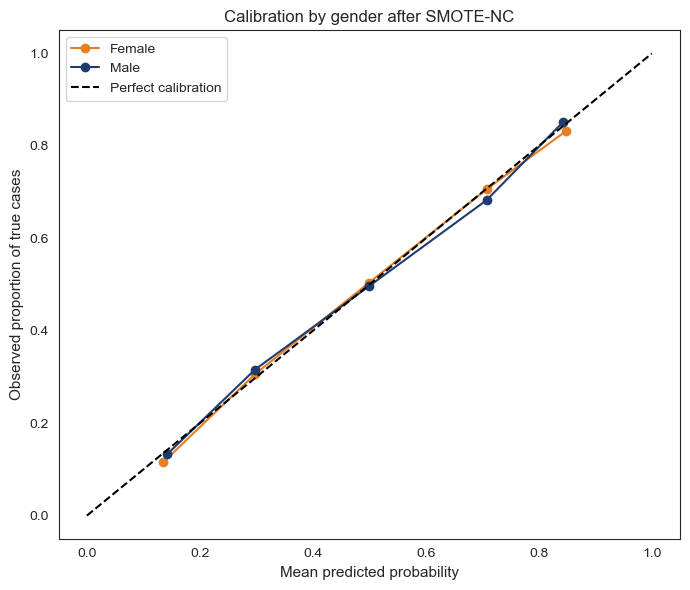

In [73]:
# Assess calibration after SMOTE-NC, using the same reliability diagram as the baseline
xgb_smote_proba = xgb_smote.predict_proba(X_test)[:, 1]

# Compute the calibration curve for each gender, using the same masks as the gender analysis
female_prob_true, female_prob_pred = calibration_curve(y_test[female_mask.values], xgb_smote_proba[female_mask.values], n_bins=5)
male_prob_true, male_prob_pred = calibration_curve(y_test[male_mask.values], xgb_smote_proba[male_mask.values], n_bins=5)

# Plot the two reliability curves together with the diagonal line for perfect calibration
plt.figure(figsize=(7, 6))
plt.plot(female_prob_pred, female_prob_true, marker='o', color='#e67e22', label='Female')
plt.plot(male_prob_pred, male_prob_true, marker='o', color='#1f3b6f', label='Male')
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfect calibration')
plt.title('Calibration by gender after SMOTE-NC')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed proportion of true cases')
plt.legend()
plt.tight_layout()
plt.show()

The calibration picture barely changes after SMOTE-NC. Both curves still sit close to each other and follow the diagonal in much the same way as the baseline. Oversampling has therefore not introduced any new calibration gap between the two genders: the predicted probabilities still mean broadly the same thing for women and men. This matches the minimal effect seen in the other metrics, since the model has changed only slightly.

### Reweighting the training data

The second method also works on the training data, but it targets the link between gender and the outcome directly rather than the balance between the disease classes. The idea is that if gender and cardiovascular disease are strongly associated in the training data, the model will learn to lean on gender, so each patient is given a weight that loosens this association before training. Patients from a gender and outcome combination that is over-represented are given a weight below one, and patients from a combination that is under-represented are given a weight above one, so that after weighting gender and the outcome look statistically independent.

The weight for each group is the rate that would be expected if gender and the outcome were independent, divided by the rate actually observed in the training data. This gives four weights, one for each combination of gender and disease status, which are then passed to the model during training. Unlike oversampling, no new patients are created and none are removed, so the same patients are used with different weights. The weighting is computed from the training data only, and the fairness metrics are then measured on the untouched test set as before.

In [74]:
# Compute a weight for each training patient so that gender and the outcome become independent
# The gender column is at index 1 in the scaled training data, with 0 for female and 1 for male
gender_train = X_train[:, 1]
n_train = len(y_train)
sample_weights = np.zeros(n_train)

# For each combination of gender and outcome, the weight is the expected rate under independence divided by the observed rate
for s in [0, 1]:
    for c in [0, 1]:
        p_gender = (gender_train == s).mean()
        p_class = (y_train.values == c).mean()
        p_joint = ((gender_train == s) & (y_train.values == c)).mean()
        group_weight = (p_gender * p_class) / p_joint
        group_mask = (gender_train == s) & (y_train.values == c)
        sample_weights[group_mask] = group_weight

# Show the four group weights to confirm the under-represented groups are weighted up
print('Weight for each gender and outcome group:')
for s in [0, 1]:
    for c in [0, 1]:
        gender_name = 'Female' if s == 0 else 'Male'
        class_name = 'no disease' if c == 0 else 'disease'
        group_mask = (gender_train == s) & (y_train.values == c)
        print('{} with {}: weight {:.4f}'.format(gender_name, class_name, sample_weights[group_mask][0]))

Weight for each gender and outcome group:
Female with no disease: weight 0.9963
Female with disease: weight 1.0038
Male with no disease: weight 1.0070
Male with disease: weight 0.9929


In [75]:
# Train a new XGBoost on the weighted training data, keeping the same tuned settings as before
xgb_reweight = XGBClassifier(max_depth=best_xgb_depth, learning_rate=0.05, n_estimators=150, random_state=random_state, eval_metric='logloss')
xgb_reweight.fit(X_train, y_train, sample_weight=sample_weights)

# Predict on the untouched test set so the evaluation reflects the real population
xgb_reweight_pred = xgb_reweight.predict(X_test)

# Measure the same four fairness metrics as before, now after reweighting
reweight_dp = demographic_parity_difference(y_test, xgb_reweight_pred, sensitive_features=gender_labels)
reweight_eo = equalized_odds_difference(y_test, xgb_reweight_pred, sensitive_features=gender_labels)
reweight_di = demographic_parity_ratio(y_test, xgb_reweight_pred, sensitive_features=gender_labels)

# Predictive parity has no direct function, so it is the difference in precision between the two groups
reweight_precision_by_gender = MetricFrame(metrics=precision_score,
                                           y_true=y_test,
                                           y_pred=xgb_reweight_pred,
                                           sensitive_features=gender_labels)
reweight_pp = reweight_precision_by_gender.difference()

# Report the test performance and the fairness metrics after reweighting
print('Accuracy after reweighting: {:.4f}'.format(accuracy_score(y_test, xgb_reweight_pred)))
print('Recall after reweighting: {:.4f}'.format(recall_score(y_test, xgb_reweight_pred)))
print('\nDemographic parity difference: {:.4f}'.format(reweight_dp))
print('Equalised odds difference: {:.4f}'.format(reweight_eo))
print('Predictive parity difference: {:.4f}'.format(reweight_pp))
print('Disparate impact ratio: {:.4f}'.format(reweight_di))

Accuracy after reweighting: 0.7305
Recall after reweighting: 0.6785

Demographic parity difference: 0.0046
Equalised odds difference: 0.0030
Predictive parity difference: 0.0136
Disparate impact ratio: 0.9898


Reweighting has almost no effect here, in contrast to a setting where the base rates differ and it is the strongest of the three methods. All four weights come out close to one, between 0.9929 and 1.0070, because gender and the outcome are already almost independent in the training data, so there is very little association for the method to loosen. The fairness metrics barely move as a result: the demographic parity difference edges from 0.0094 to 0.0046, the disparate impact ratio from 0.9792 to 0.9898, and the equalised odds and predictive parity differences stay near where they were, at 0.0030 and 0.0136. Every metric remains close to fair.

This is the same story as oversampling, seen from a different angle. Where the base rates differ, reweighting gives the under-represented group a large weight and forces a sharp trade-off between the metrics; here the near-equal base rates leave every weight close to one, so the method has almost nothing to change. The effect on performance is again minimal, with test accuracy at 0.7305 and recall at 0.6785. Because gender and the outcome are barely linked to begin with, loosening that link does not move the model or its fairness metrics in any meaningful way.

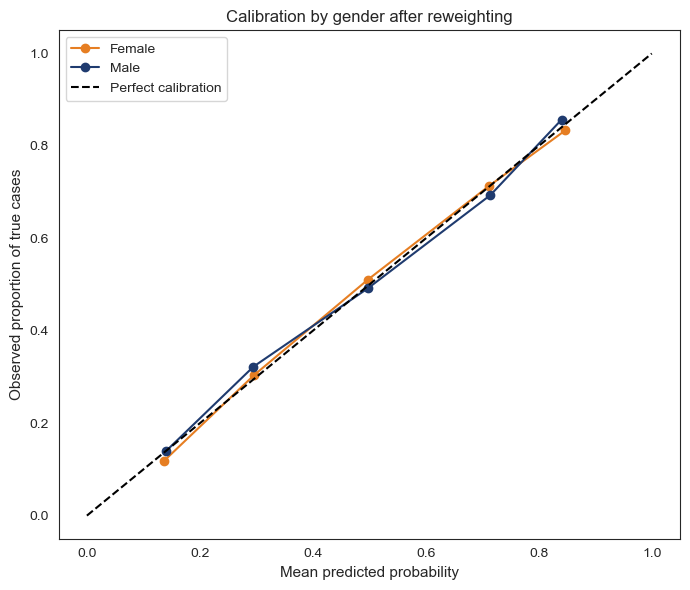

In [76]:
# Assess calibration after reweighting, using the same reliability diagram as the baseline
xgb_reweight_proba = xgb_reweight.predict_proba(X_test)[:, 1]

# Compute the calibration curve for each gender, using the same masks as the gender analysis
female_prob_true, female_prob_pred = calibration_curve(y_test[female_mask.values], xgb_reweight_proba[female_mask.values], n_bins=5)
male_prob_true, male_prob_pred = calibration_curve(y_test[male_mask.values], xgb_reweight_proba[male_mask.values], n_bins=5)

# Plot the two reliability curves together with the diagonal line for perfect calibration
plt.figure(figsize=(7, 6))
plt.plot(female_prob_pred, female_prob_true, marker='o', color='#e67e22', label='Female')
plt.plot(male_prob_pred, male_prob_true, marker='o', color='#1f3b6f', label='Male')
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfect calibration')
plt.title('Calibration by gender after reweighting')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed proportion of true cases')
plt.legend()
plt.tight_layout()
plt.show()

The calibration picture barely changes after reweighting. Both curves still sit close to each other and follow the diagonal in much the same way as the baseline and the oversampled model. Reweighting has therefore not introduced any calibration gap between the two genders: the predicted probabilities still mean broadly the same thing for women and men. This follows from the weights being close to one, which leaves the model and the probabilities it assigns almost unchanged.

This is worth noting alongside the other metrics. Where the base rates differ, reweighting can worsen calibration at the same time as predictive parity, so that improving the error-rate metrics carries a cost on two fronts at once. Here there is no such cost, because the method barely changes the model: with the genders and the outcome already almost independent, there is nothing for reweighting to trade away, and calibration stays intact alongside the other fairness metrics.

### Adjusting the decision threshold

The third method is different from the first two: it does not touch the training data or retrain the model at all. Instead it takes the already-trained XGBoost and changes only the decision threshold, the cut-off above which a predicted probability becomes a positive prediction. The earlier ROC analysis showed that the model ranks female and male patients about equally well and applies a single shared threshold that already treats them almost the same, so unlike the setting where the base rates differ there is no clear gap for a per-group threshold to close. This method is included so that the same post-processing step is examined on both datasets.

The threshold for each group is chosen to bring the true positive and false positive rates closer together across the genders, which is the equalised odds constraint, while keeping the balanced accuracy as high as possible. Because the model itself is left unchanged, the predicted probabilities do not change, so calibration is not re-examined here: only the cut-off applied to those probabilities differs by group. One limitation should be stated plainly. This method needs the gender of each patient at the moment a prediction is made, since the threshold depends on it. Setting a different diagnostic cut-off by gender may be inappropriate or even legally restricted in a real clinical setting, so this is presented as a way to surface the trade-off rather than as a deployable solution.

In [77]:
# Suppress the pandas FutureWarning raised inside Fairlearn during threshold prediction
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Import the post-processing tool that adjusts the decision threshold per group
from fairlearn.postprocessing import ThresholdOptimizer

# Wrap the already-trained XGBoost and adjust the threshold separately for each gender
# The equalised odds constraint matches the true and false positive rates across the genders, and balanced accuracy is kept as the objective
threshold_optimizer = ThresholdOptimizer(estimator=tuned_xgb, constraints='equalized_odds', objective='balanced_accuracy_score', prefit=True, predict_method='predict_proba')

# Fit uses the training data and the gender labels, but does not retrain the model itself
gender_labels_train = pd.Series(X_train[:, 1]).map({0: 'Female', 1: 'Male'})
threshold_optimizer.fit(X_train, y_train, sensitive_features=gender_labels_train)

# Predict on the test set, passing the gender of each patient so the right threshold is applied
threshold_pred = threshold_optimizer.predict(X_test, sensitive_features=gender_labels, random_state=random_state)

# Measure the same four fairness metrics as before, now after threshold optimisation
threshold_dp = demographic_parity_difference(y_test, threshold_pred, sensitive_features=gender_labels)
threshold_eo = equalized_odds_difference(y_test, threshold_pred, sensitive_features=gender_labels)
threshold_di = demographic_parity_ratio(y_test, threshold_pred, sensitive_features=gender_labels)

# Predictive parity has no direct function, so it is the difference in precision between the two groups
threshold_precision_by_gender = MetricFrame(metrics=precision_score,
                                            y_true=y_test,
                                            y_pred=threshold_pred,
                                            sensitive_features=gender_labels)
threshold_pp = threshold_precision_by_gender.difference()

# Report the test performance and the fairness metrics after threshold optimisation
print('Accuracy after threshold optimisation: {:.4f}'.format(accuracy_score(y_test, threshold_pred)))
print('Recall after threshold optimisation: {:.4f}'.format(recall_score(y_test, threshold_pred)))
print('\nDemographic parity difference: {:.4f}'.format(threshold_dp))
print('Equalised odds difference: {:.4f}'.format(threshold_eo))
print('Predictive parity difference: {:.4f}'.format(threshold_pp))
print('Disparate impact ratio: {:.4f}'.format(threshold_di))

Accuracy after threshold optimisation: 0.7295
Recall after threshold optimisation: 0.6792

Demographic parity difference: 0.0067
Equalised odds difference: 0.0007
Predictive parity difference: 0.0123
Disparate impact ratio: 0.9851


Threshold optimisation also has only a small effect here. The equalised odds difference drops to 0.0007, the lowest of any method, which makes sense because this method was set up with the equalised odds constraint, but it was already close to zero so there was little to do. The demographic parity difference edges to 0.0067 and the disparate impact ratio to 0.9851, both slightly fairer, while predictive parity barely moves, at 0.0123. Recall stays close to the baseline at 0.6792, since the model itself is untouched and only the cut-off has moved.

There is no real trade-off to see here, in contrast to the setting where the base rates differ and pushing the selection and error-rate metrics towards equality comes at a clear cost to predictive parity. Because the genders were already treated almost the same, the per-group thresholds end up very close together and every metric stays near fair. Calibration is not re-examined, since this method changes only the threshold and not the predicted probabilities, so their reliability is unchanged from the baseline.

One limitation still carries weight in a clinical context. Because a different threshold is applied for each gender, the method needs to know the patient's gender at the moment of prediction, and using a different diagnostic cut-off by gender may be inappropriate or legally restricted in practice. This method is therefore best read as a way to show how the trade-off can be shifted, rather than as something that would be deployed directly.

### Comparing the mitigation methods



The three mitigation methods are now placed side by side with the baseline, so that the effect of each can be compared directly across the four fairness metrics and the two performance measures. This makes the pattern visible in a single table: because the baseline is already close to fair, each method leaves the metrics near where they started rather than forcing the trade-off between them that appears when the base rates differ.

In [78]:
# Build a comparison table with the baseline and the three mitigation methods side by side
mitigation_comparison = pd.DataFrame({
    'Baseline': [dp_difference, eo_difference, pp_difference, di_ratio,
                 accuracy_score(y_test, tuned_xgb_pred), recall_score(y_test, tuned_xgb_pred)],
    'SMOTE-NC': [smote_dp, smote_eo, smote_pp, smote_di,
                 accuracy_score(y_test, xgb_smote_pred), recall_score(y_test, xgb_smote_pred)],
    'Reweighting': [reweight_dp, reweight_eo, reweight_pp, reweight_di,
                    accuracy_score(y_test, xgb_reweight_pred), recall_score(y_test, xgb_reweight_pred)],
    'ThresholdOptimizer': [threshold_dp, threshold_eo, threshold_pp, threshold_di,
                           accuracy_score(y_test, threshold_pred), recall_score(y_test, threshold_pred)]
}, index=['Demographic parity difference', 'Equalised odds difference', 'Predictive parity difference', 'Disparate impact ratio', 'Accuracy', 'Recall'])

# Show the comparison rounded to four decimals for readability
print('Mitigation comparison on the test set:\n{}'.format(mitigation_comparison.round(4)))

Mitigation comparison on the test set:
                               Baseline  SMOTE-NC  Reweighting  \
Demographic parity difference    0.0094    0.0079       0.0046   
Equalised odds difference        0.0024    0.0034       0.0030   
Predictive parity difference     0.0110    0.0085       0.0136   
Disparate impact ratio           0.9792    0.9828       0.9898   
Accuracy                         0.7288    0.7301       0.7305   
Recall                           0.6782    0.6829       0.6785   

                               ThresholdOptimizer  
Demographic parity difference              0.0067  
Equalised odds difference                  0.0007  
Predictive parity difference               0.0123  
Disparate impact ratio                     0.9851  
Accuracy                                   0.7295  
Recall                                     0.6792  


The table makes the central pattern of the project visible in one place. Reading across the four methods, every metric stays close to fair: the predictive parity difference only ranges between 0.0085 and 0.0136, while demographic parity, equalised odds and the disparate impact ratio all stay near their fair values throughout. No method has to trade one metric against another. This is the impossibility result seen from the other side: because the base rates between the two genders are almost equal, the condition that forces the metrics into conflict is absent, so the methods leave a model that was already fair still fair.

The methods differ very little in their effect. Oversampling changes almost nothing, since the training set was already close to balanced. Reweighting leaves every weight close to one and introduces no calibration gap, unlike the setting where the base rates differ and it overestimates risk for one group. Threshold optimisation brings the equalised odds difference down to its lowest value of 0.0007, but it was already near zero, so there is little to gain. None of the methods buys fairness on one metric at the cost of another, and accuracy stays stable at around 0.73 throughout.

None of the three methods needs to remove unfairness here, because there is no real unfairness to remove. This is the point the project sets out to make: under near-equal base rates there is no conflict between the fairness measures, so the methods simply confirm that the model is fair on all of them at once. This is the other side of the impossibility result, where the trade-off appears only when the base rates differ. It is what motivates a dashboard that lets the trade-off be explored where it exists rather than fixed at a single point. Because both groups are large, with 8990 female and 4741 male patients, these results can be read with confidence.

## 10. Saving the Dashboard Data

The analysis is now complete. This final step saves the results that the dashboard depends on, so that the dashboard can load them directly rather than repeating the training and the explanations each time it runs. The predicted probabilities are saved for the baseline model and for the two mitigation models, together with the threshold-optimised predictions, along with the gender-stratified SHAP importances, the calibration curves for the baseline and the two mitigation methods, and the full-dataset disease rate for each gender. Together these are the outputs the dashboard presents.

In [79]:
# Save the values that the dashboard needs, so it can be built without repeating the analysis
# Nothing heavy is recomputed here, the existing results are simply written to disk
save_dir = '../dashboard/dashboard_data/'

# Save the predicted probability for each patient, from the baseline model and from the two mitigation models
# The baseline probability is kept so the metrics can be recalculated at any threshold, and the mitigation ones show how each method changes the outcome
# The threshold-optimised predictions are also kept, since that method returns a decision rather than a probability
proba_df = pd.DataFrame({'probability': tuned_xgb_proba,
                         'probability_smote': xgb_smote_proba,
                         'probability_reweight': xgb_reweight_proba,
                         'threshold_pred': threshold_pred,
                         'gender': X_test_df['gender'].values,
                         'y_true': y_test.values})
proba_df.to_csv(save_dir + 'kaggle_probabilities.csv', index=False)
print('Saved probabilities for {} patients'.format(proba_df.shape[0]))

# Save the mean absolute SHAP value of each feature for the female and male patients separately
# These come from the same gender-stratified SHAP values plotted earlier, so the two rankings can be compared again
female_importance = pd.DataFrame(female_shap_xgb, columns=X.columns).abs().mean()
male_importance = pd.DataFrame(male_shap_xgb, columns=X.columns).abs().mean()
shap_summary = pd.DataFrame({'feature': X.columns,
                             'female': female_importance.values,
                             'male': male_importance.values})
shap_summary.to_csv(save_dir + 'kaggle_shap_gender.csv', index=False)
print('Saved gender-stratified SHAP for {} features'.format(shap_summary.shape[0]))

# Recompute and save the calibration here, because the mitigation section overwrote the calibration variables
# The calibration is saved for the baseline and for the two mitigation methods, so the dashboard can show how each one shifts it
# The threshold optimiser is left out, since it returns a decision rather than a probability and so has no calibration curve
calibration_probabilities = {'baseline': tuned_xgb_proba, 'smote': xgb_smote_proba, 'reweight': xgb_reweight_proba}
for method in calibration_probabilities:
    method_proba = calibration_probabilities[method]
    female_prob_true, female_prob_pred = calibration_curve(y_test[female_mask.values], method_proba[female_mask.values], n_bins=5)
    male_prob_true, male_prob_pred = calibration_curve(y_test[male_mask.values], method_proba[male_mask.values], n_bins=5)
    female_calib = pd.DataFrame({'prob_pred': female_prob_pred, 'prob_true': female_prob_true})
    female_calib.to_csv(save_dir + 'kaggle_calibration_female_{}.csv'.format(method), index=False)
    male_calib = pd.DataFrame({'prob_pred': male_prob_pred, 'prob_true': male_prob_true})
    male_calib.to_csv(save_dir + 'kaggle_calibration_male_{}.csv'.format(method), index=False)
print('Saved calibration points for both genders across the baseline and the two mitigation methods')

# Save the full-dataset disease rate for each gender, computed from all patients before the train and test split
# This is the base rate the report quotes, and it is fixed context that does not change with the threshold
base_rate = df.groupby('gender')['target'].mean()
base_rate_df = pd.DataFrame({'group': ['Female', 'Male'],
                             'disease_rate': [base_rate[0], base_rate[1]]})
base_rate_df.to_csv(save_dir + 'kaggle_base_rate.csv', index=False)
print('Saved base rates: Female {:.4f}, Male {:.4f}'.format(base_rate[0], base_rate[1]))

print('\nAll dashboard data saved to {}'.format(save_dir))

Saved probabilities for 13731 patients
Saved gender-stratified SHAP for 11 features
Saved calibration points for both genders across the baseline and the two mitigation methods
Saved base rates: Female 0.4921, Male 0.4996

All dashboard data saved to ../dashboard/dashboard_data/
